In [ ]:

from google.colab import files

uploaded = files.upload()

print("\nSuccessfully uploaded files:")
for filename in uploaded.keys():
    print(filename)


Saving studentInfo.csv to studentInfo.csv
Saving studentRegistration.csv to studentRegistration.csv

Successfully uploaded files:
studentInfo.csv
studentRegistration.csv


In [ ]:
import os

print("Files available in Colab:")
print(os.listdir("/content"))


Files available in Colab:
['.config', 'studentRegistration.csv', 'studentInfo.csv', '.ipynb_checkpoints', 'sample_data']


In [ ]:
import pandas as pd

# Load both OULAD datasets
student_info = pd.read_csv("/content/studentInfo.csv")
student_registration = pd.read_csv("/content/studentRegistration.csv")

print("=" * 55)
print("DATASET 1: STUDENT INFORMATION")
print("=" * 55)

print("Total Rows:", student_info.shape[0])
print("Total Columns:", student_info.shape[1])
print("\nColumn Names:")
print(student_info.columns.tolist())

print("\nFirst 5 Records:")
display(student_info.head())

print("\n" + "=" * 55)
print("DATASET 2: STUDENT REGISTRATION")
print("=" * 55)

print("Total Rows:", student_registration.shape[0])
print("Total Columns:", student_registration.shape[1])
print("\nColumn Names:")
print(student_registration.columns.tolist())

print("\nFirst 5 Records:")
display(student_registration.head())


DATASET 1: STUDENT INFORMATION
Total Rows: 32593
Total Columns: 12

Column Names:
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']

First 5 Records:


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass



DATASET 2: STUDENT REGISTRATION
Total Rows: 32593
Total Columns: 5

Column Names:
['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']

First 5 Records:


,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0
3,AAA,2013J,31604,-52.0,NaN
4,AAA,2013J,32885,-176.0,NaN


In [ ]:

print("=" * 55)
print("INITIAL DATASET REQUIREMENT CHECK")
print("=" * 55)

print("Minimum Required Rows: 5000")
print("Available Student Records:", len(student_info))

print("\nMinimum Required Features: 15")
print("Current Student Information Columns:",
      student_info.shape[1])

print("\nRow Requirement:",
      "PASS" if len(student_info) >= 5000 else "FAIL")

print("15 Feature Requirement:",
      "PASS" if student_info.shape[1] >= 15 else "NOT YET")


INITIAL DATASET REQUIREMENT CHECK
Minimum Required Rows: 5000
Available Student Records: 32593

Minimum Required Features: 15
Current Student Information Columns: 12

Row Requirement: PASS
15 Feature Requirement: NOT YET


In [ ]:
import pandas as pd

merge_keys = [
    "code_module",
    "code_presentation",
    "id_student"
]

# Check duplicate keys before merging
print("Duplicate keys in studentInfo:",
      student_info.duplicated(subset=merge_keys).sum())

print("Duplicate keys in studentRegistration:",
      student_registration.duplicated(subset=merge_keys).sum())

# Merge datasets using all three keys
merged_data = pd.merge(
    student_info,
    student_registration,
    on=merge_keys,
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\nMERGE VERIFICATION")
print("-" * 50)

print("Original rows:", len(student_info))
print("Merged rows:", len(merged_data))

print("\nMerge status:")
print(merged_data["_merge"].value_counts())

# Verify no records were lost or duplicated
assert len(merged_data) == len(student_info), \
    "ERROR: Row count changed after merging!"

assert (merged_data["_merge"] == "both").all(), \
    "ERROR: Some registration records were not matched!"

# Remove temporary merge indicator
merged_data = merged_data.drop(columns=["_merge"])

print("\nMERGE SUCCESSFUL!")
print("Final shape:", merged_data.shape)

print("\nFirst 5 merged records:")
display(merged_data.head())


Duplicate keys in studentInfo: 0
Duplicate keys in studentRegistration: 0

MERGE VERIFICATION
--------------------------------------------------
Original rows: 32593
Merged rows: 32593

Merge status:
_merge
both          32593
left_only         0
right_only        0
Name: count, dtype: int64

MERGE SUCCESSFUL!
Final shape: (32593, 14)

First 5 merged records:


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,date_registration,date_unregistration
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,-159.0,NaN
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,-53.0,NaN
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,-92.0,12.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,-52.0,NaN
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,-176.0,NaN


In [ ]:
print("=" * 55)
print("MERGED DATA QUALITY REPORT")
print("=" * 55)

print("\nDataset shape:")
print(merged_data.shape)

print("\nMissing values per column:")
print(merged_data.isnull().sum())

print("\nFinal result distribution:")
print(merged_data["final_result"].value_counts())

print("\nFinal result percentages:")
print(
    merged_data["final_result"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nUnique students:",
      merged_data["id_student"].nunique())

print("\nDuplicate student-course records:",
      merged_data.duplicated(subset=merge_keys).sum())


MERGED DATA QUALITY REPORT

Dataset shape:
(32593, 14)

Missing values per column:
code_module                 0
code_presentation           0
id_student                  0
gender                      0
region                      0
highest_education           0
imd_band                 1111
age_band                    0
num_of_prev_attempts        0
studied_credits             0
disability                  0
final_result                0
date_registration          45
date_unregistration     22521
dtype: int64

Final result distribution:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

Final result percentages:
final_result
Pass           37.93
Withdrawn      31.16
Fail           21.64
Distinction     9.28
Name: proportion, dtype: float64

Unique students: 28785

Duplicate student-course records: 0


In [ ]:

from google.colab import files

print("Upload assessments.csv and studentAssessment.csv")
uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)


Upload assessments.csv and studentAssessment.csv


Saving assessments.csv to assessments.csv
Saving studentAssessment.csv to studentAssessment.csv

Uploaded files:
assessments.csv
studentAssessment.csv


In [ ]:
import pandas as pd

assessments = pd.read_csv("/content/assessments.csv")
student_assessment = pd.read_csv("/content/studentAssessment.csv")

print("=" * 55)
print("ASSESSMENTS DATASET")
print("=" * 55)

print("Shape:", assessments.shape)
print("\nColumns:")
print(assessments.columns.tolist())
print("\nFirst 5 records:")
display(assessments.head())

print("\n" + "=" * 55)
print("STUDENT ASSESSMENT DATASET")
print("=" * 55)

print("Shape:", student_assessment.shape)
print("\nColumns:")
print(student_assessment.columns.tolist())
print("\nFirst 5 records:")
display(student_assessment.head())

print("\nMissing values:")
print(student_assessment.isnull().sum())


ASSESSMENTS DATASET
Shape: (206, 6)

Columns:
['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']

First 5 records:


,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0



STUDENT ASSESSMENT DATASET
Shape: (173912, 5)

Columns:
['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

First 5 records:


,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0



Missing values:
id_assessment       0
id_student          0
date_submitted      0
is_banked           0
score             173
dtype: int64


In [ ]:
import pandas as pd
import numpy as np

keys = ["code_module", "code_presentation", "id_student"]

# Merge assessment metadata with student submissions
assessment_records = student_assessment.merge(
    assessments,
    on="id_assessment",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Verify all assessments matched
assert (assessment_records["_merge"] == "both").all(), \
    "Some assessment IDs did not match!"

assessment_records = assessment_records.drop(columns="_merge")

print("Total assessment records:", len(assessment_records))

# Only consider assessments submitted within first 30 days
# and assessments scheduled within the first 30 days
early_assessments = assessment_records[
    (assessment_records["date_submitted"] <= 30) &
    (assessment_records["date"] <= 30) &
    (assessment_records["date_submitted"] >= 0) &
    (assessment_records["is_banked"] == 0)
].copy()

print("Early assessment records:", len(early_assessments))

# Aggregate per student-course enrollment
assessment_features = early_assessments.groupby(
    keys
).agg(
    early_assessment_count=("id_assessment", "count"),
    early_avg_score=("score", "mean"),
    early_max_score=("score", "max"),
    early_min_score=("score", "min"),
    early_score_std=("score", "std"),
    early_total_weight=("weight", "sum"),
    early_avg_submission_day=("date_submitted", "mean")
).reset_index()

print("\nAssessment feature dataset shape:",
      assessment_features.shape)

print("\nFirst five records:")
display(assessment_features.head())


Total assessment records: 173912
Early assessment records: 20971

Assessment feature dataset shape: (20073, 10)

First five records:


,code_module,code_presentation,id_student,early_assessment_count,early_avg_score,early_max_score,early_min_score,early_score_std,early_total_weight,early_avg_submission_day
0,AAA,2013J,11391,1,78.0,78.0,78.0,NaN,10.0,18.0
1,AAA,2013J,28400,1,70.0,70.0,70.0,NaN,10.0,22.0
2,AAA,2013J,31604,1,72.0,72.0,72.0,NaN,10.0,17.0
3,AAA,2013J,32885,1,69.0,69.0,69.0,NaN,10.0,26.0
4,AAA,2013J,38053,1,79.0,79.0,79.0,NaN,10.0,19.0


In [ ]:
model_data = merged_data.merge(
    assessment_features,
    on=keys,
    how="left",
    validate="one_to_one"
)

assert len(model_data) == len(merged_data), \
    "Row count changed unexpectedly!"

print("Merged dataset shape:", model_data.shape)

print("\nMissing values in new features:")
print(
    model_data[
        assessment_features.columns.difference(keys)
    ].isnull().sum()
)

print("\nFirst five records:")
display(model_data.head())


Merged dataset shape: (32593, 21)

Missing values in new features:
early_assessment_count      12520
early_avg_score             12533
early_avg_submission_day    12520
early_max_score             12533
early_min_score             12533
early_score_std             31697
early_total_weight          12520
dtype: int64

First five records:


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,final_result,date_registration,date_unregistration,early_assessment_count,early_avg_score,early_max_score,early_min_score,early_score_std,early_total_weight,early_avg_submission_day
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,Pass,-159.0,NaN,1.0,78.0,78.0,78.0,NaN,10.0,18.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,Pass,-53.0,NaN,1.0,70.0,70.0,70.0,NaN,10.0,22.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,Withdrawn,-92.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,Pass,-52.0,NaN,1.0,72.0,72.0,72.0,NaN,10.0,17.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,Pass,-176.0,NaN,1.0,69.0,69.0,69.0,NaN,10.0,26.0


In [ ]:
excluded_columns = [
    "id_student",
    "final_result",
    "date_unregistration"
]

candidate_features = [
    col for col in model_data.columns
    if col not in excluded_columns
]

print("Total dataset rows:", len(model_data))
print("Candidate input features:", len(candidate_features))

print("\nFeature names:")
for i, feature in enumerate(candidate_features, 1):
    print(f"{i}. {feature}")

print("\nRow requirement:",
      "PASS" if len(model_data) >= 5000 else "FAIL")

print("15-feature requirement:",
      "PASS (candidate only)"
      if len(candidate_features) >= 15 else "FAIL")


Total dataset rows: 32593
Candidate input features: 18

Feature names:
1. code_module
2. code_presentation
3. gender
4. region
5. highest_education
6. imd_band
7. age_band
8. num_of_prev_attempts
9. studied_credits
10. disability
11. date_registration
12. early_assessment_count
13. early_avg_score
14. early_max_score
15. early_min_score
16. early_score_std
17. early_total_weight
18. early_avg_submission_day

Row requirement: PASS
15-feature requirement: PASS (candidate only)


In [ ]:
import numpy as np
import pandas as pd

PREDICTION_DAY = 30

# Start from the existing merged dataset
eligible_data = model_data.copy()

# Keep students registered by Day 30
eligible_data = eligible_data[
    eligible_data["date_registration"].notna() &
    (eligible_data["date_registration"] <= PREDICTION_DAY)
].copy()

# Exclude students who withdrew on or before Day 30
eligible_data = eligible_data[
    eligible_data["date_unregistration"].isna() |
    (eligible_data["date_unregistration"] > PREDICTION_DAY)
].copy()

# Binary target: future course withdrawal
eligible_data["dropout_risk"] = (
    eligible_data["final_result"] == "Withdrawn"
).astype(int)

print("=" * 55)
print("DAY-30 ELIGIBLE DATASET")
print("=" * 55)

print("Original rows:", len(model_data))
print("Eligible rows:", len(eligible_data))
print("Excluded rows:", len(model_data) - len(eligible_data))

print("\nTarget distribution:")
print(eligible_data["dropout_risk"].value_counts())

print("\nTarget percentages:")
print(
    eligible_data["dropout_risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nRequirement checks:")
print("5,000+ rows:",
      len(eligible_data) >= 5000)

print("Target contains both classes:",
      eligible_data["dropout_risk"].nunique() == 2)


DAY-30 ELIGIBLE DATASET
Original rows: 32593
Eligible rows: 27443
Excluded rows: 5150

Target distribution:
dropout_risk
0    22410
1     5033
Name: count, dtype: int64

Target percentages:
dropout_risk
0    81.66
1    18.34
Name: proportion, dtype: float64

Requirement checks:
5,000+ rows: True
Target contains both classes: True


In [ ]:
excluded_columns = [
    "id_student",
    "final_result",
    "date_unregistration",
    "dropout_risk",
    "early_score_std"
]

feature_columns = [
    col for col in eligible_data.columns
    if col not in excluded_columns
]

print("Final candidate feature count:", len(feature_columns))

print("\nCandidate features:")
for i, col in enumerate(feature_columns, start=1):
    print(f"{i}. {col}")

print("\nMissing values:")
print(
    eligible_data[feature_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

assert "date_unregistration" not in feature_columns
assert "final_result" not in feature_columns
assert "id_student" not in feature_columns
assert len(feature_columns) >= 15

print("\nBasic leakage checks passed.")


Final candidate feature count: 17

Candidate features:
1. code_module
2. code_presentation
3. gender
4. region
5. highest_education
6. imd_band
7. age_band
8. num_of_prev_attempts
9. studied_credits
10. disability
11. date_registration
12. early_assessment_count
13. early_avg_score
14. early_max_score
15. early_min_score
16. early_total_weight
17. early_avg_submission_day

Missing values:
early_max_score             7788
early_avg_score             7788
early_min_score             7788
early_avg_submission_day    7783
early_assessment_count      7783
early_total_weight          7783
imd_band                    1026
code_module                    0
code_presentation              0
studied_credits                0
num_of_prev_attempts           0
age_band                       0
highest_education              0
gender                         0
region                         0
disability                     0
date_registration              0
dtype: int64

Basic leakage checks passed.


In [ ]:
output_path = "/content/student_dropout_day30_candidate.csv"

eligible_data.to_csv(output_path, index=False)

print("Candidate dataset saved successfully!")
print("File:", output_path)
print("Rows:", len(eligible_data))
print("Columns:", eligible_data.shape[1])


Candidate dataset saved successfully!
File: /content/student_dropout_day30_candidate.csv
Rows: 27443
Columns: 22


In [ ]:
from google.colab import files

print("Upload the UCI data.csv file")
uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print(filename)


Upload the UCI data.csv file


Saving data.csv to data.csv

Uploaded files:
data.csv


In [ ]:
import pandas as pd

uci_data = pd.read_csv("/content/data.csv", sep=";")

print("=" * 55)
print("UCI DATASET INSPECTION")
print("=" * 55)

print("Shape:", uci_data.shape)

print("\nColumns:")
for i, col in enumerate(uci_data.columns, 1):
    print(f"{i}. {col}")

print("\nFirst 5 rows:")
display(uci_data.head())

print("\nTarget distribution:")
if "Target" in uci_data.columns:
    print(uci_data["Target"].value_counts())
else:
    print("Target column not found. Check CSV format.")

print("\nMissing values:")
print(uci_data.isnull().sum().sort_values(ascending=False).head(15))


UCI DATASET INSPECTION
Shape: (4424, 37)

Columns:
1. Marital status
2. Application mode
3. Application order
4. Course
5. Daytime/evening attendance	
6. Previous qualification
7. Previous qualification (grade)
8. Nacionality
9. Mother's qualification
10. Father's qualification
11. Mother's occupation
12. Father's occupation
13. Admission grade
14. Displaced
15. Educational special needs
16. Debtor
17. Tuition fees up to date
18. Gender
19. Scholarship holder
20. Age at enrollment
21. International
22. Curricular units 1st sem (credited)
23. Curricular units 1st sem (enrolled)
24. Curricular units 1st sem (evaluations)
25. Curricular units 1st sem (approved)
26. Curricular units 1st sem (grade)
27. Curricular units 1st sem (without evaluations)
28. Curricular units 2nd sem (credited)
29. Curricular units 2nd sem (enrolled)
30. Curricular units 2nd sem (evaluations)
31. Curricular units 2nd sem (approved)
32. Curricular units 2nd sem (grade)
33. Curricular units 2nd sem (without evaluat

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate



Target distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Missing values:
Marital status                    0
Application mode                  0
Application order                 0
Course                            0
Daytime/evening attendance\t      0
Previous qualification            0
Previous qualification (grade)    0
Nacionality                       0
Mother's qualification            0
Father's qualification            0
Mother's occupation               0
Father's occupation               0
Admission grade                   0
Displaced                         0
Educational special needs         0
dtype: int64


In [ ]:
print("=" * 55)
print("OULAD PRESENTATION SUMMARY")
print("=" * 55)

presentation_summary = (
    eligible_data
    .groupby(["code_module", "code_presentation"])
    .agg(
        student_records=("id_student", "size"),
        withdrawals=("dropout_risk", "sum")
    )
    .reset_index()
)

presentation_summary["withdrawal_rate"] = (
    presentation_summary["withdrawals"] /
    presentation_summary["student_records"] * 100
).round(2)

display(presentation_summary)

print("\nUnique presentation codes:")
print(sorted(eligible_data["code_presentation"].unique()))

print("\nUnique modules:")
print(sorted(eligible_data["code_module"].unique()))

print("\nTotal presentation combinations:",
      len(presentation_summary))


OULAD PRESENTATION SUMMARY


,code_module,code_presentation,student_records,withdrawals,withdrawal_rate
0,AAA,2013J,368,46,12.50
1,AAA,2014J,348,49,14.08
2,BBB,2013B,1524,264,17.32
3,BBB,2013J,1825,235,12.88
4,BBB,2014B,1279,158,12.35
5,BBB,2014J,1785,243,13.61
6,CCC,2014B,1489,451,30.29
7,CCC,2014J,2011,591,29.39
8,DDD,2013B,1134,267,23.54
9,DDD,2013J,1635,382,23.36



Unique presentation codes:
['2013B', '2013J', '2014B', '2014J']

Unique modules:
['AAA', 'BBB', 'CCC', 'DDD', 'EEE', 'FFF', 'GGG']

Total presentation combinations: 22


In [ ]:
from google.colab import files

print("Upload unemployment-region Excel file")
uploaded = files.upload()

unemployment_filename = list(uploaded.keys())[0]

print("\nUploaded file:", unemployment_filename)


Upload unemployment-region Excel file


Saving unemployment-region.xlsx to unemployment-region.xlsx

Uploaded file: unemployment-region.xlsx


In [ ]:
import pandas as pd

excel_file = pd.ExcelFile(unemployment_filename)

print("=" * 55)
print("UNEMPLOYMENT DATASET INSPECTION")
print("=" * 55)

print("\nSheet names:")
print(excel_file.sheet_names)

for sheet in excel_file.sheet_names:
    print("\n" + "=" * 55)
    print("SHEET:", sheet)
    print("=" * 55)

    preview = pd.read_excel(
        unemployment_filename,
        sheet_name=sheet,
        header=None,
        nrows=12
    )

    print("Preview shape:", preview.shape)
    display(preview)


UNEMPLOYMENT DATASET INSPECTION

Sheet names:
['Metadata', 'Unemployed', 'Long-term trend']

SHEET: Metadata
Preview shape: (12, 2)


,0,1
0,Name,Number and rates of London residents aged 16+ ...
1,ShortName,Unemployment
2,NaN,NaN
3,Theme,Employment and Skills
4,Sub-theme,Unemployment
5,NaN,NaN
6,Title,Number and rates of unemployment by region
7,Description,Number of London residents aged 16+ who are IL...
8,Subject,Unemployment
9,Subject keyword,"workless, jobs, unemployment, ilo, economic i..."



SHEET: Unemployed
Preview shape: (12, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,Quarter ending,2009-04-01 00:00:00,2010-04-01 00:00:00,2011-04-01 00:00:00,2011-05-01 00:00:00,2011-06-01 00:00:00,2011-07-01 00:00:00,2011-08-01 00:00:00,2011-09-01 00:00:00,2011-10-01 00:00:00,...,2025-11-01 00:00:00,2025-12-01 00:00:00,2026-01-01 00:00:00,2026-02-01 00:00:00,2026-03-01 00:00:00,2026-04-01 00:00:00,2026-05-01 00:00:00,2026-06-01 00:00:00,2026-07-01 00:00:00,2026-08-01 00:00:00
1,Numbers ('000s),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,London,352038.836272,388583.269035,402786.885128,421043.894063,428762.212913,436310.93343,447318.512368,435675.037942,446098.599036,...,375892.086397,397504.217629,416060.654126,388361.960871,383289.901444,345648.938634,339333.663201,338918.116588,355074.380685,349328.416945
3,United Kingdom,2296411.124414,2509542.269364,2461507.78607,2500440.089803,2539721.654291,2556212.943622,2610884.301848,2662207.561814,2677777.793156,...,1839862.346231,1882886.836317,1868715.824967,1780058.064135,1805835.213082,1763813.804003,1759585.366975,1772269.562655,1778258.796381,1712314.377911
4,England,1951179.51503,2106129.792759,2072165.717879,2111012.685865,2135456.638519,2162326.760284,2188248.083566,2234984.674238,2238625.007729,...,1633832.069392,1688824.962735,1685776.941591,1588275.742523,1608259.968891,1569772.577205,1542837.802874,1538856.412365,1548060.270924,1519724.46056
5,Wales,112207.163282,124975.598024,116017.318553,117331.919745,125112.554558,124710.896915,137774.204654,144619.701481,139516.542836,...,84333.323851,69501.397585,54278.771022,59836.09132,56283.510727,58874.162816,67623.162392,75125.554329,68444.126607,53943.616648
6,Scotland,181772.666279,218732.592786,211421.979889,210318.187948,215350.905269,205535.662123,219193.005177,219343.648404,239075.611276,...,102511.599384,104461.226718,108867.402286,112201.497904,122513.810623,119374.594595,132135.531358,140301.222477,140077.486009,118940.468166
7,Northern Ireland,51251.779823,59704.285795,61902.769748,61777.296245,63801.555944,63639.6243,65430.260854,62782.042498,59844.388525,...,19185.353604,20099.249279,19792.710068,19744.732388,18777.922841,15792.469386,16988.870351,17986.373484,21676.912841,19705.832538
8,North East,102668.464465,121257.437668,114421.792946,120420.165852,126592.164676,134684.007361,138560.435847,145603.96592,146118.180212,...,82228.331065,91620.865897,94603.478325,81171.218086,73488.840506,71238.391043,76671.799588,71410.28493,68866.529491,62238.52356
9,North West,280519.696487,294776.428104,277899.781978,293638.079054,302984.455946,287698.690116,290382.786567,301156.348024,308005.001407,...,196846.653747,200788.511294,184247.727919,182040.296335,193455.757032,199935.511592,190703.546313,199940.55446,200183.292798,184904.258734



SHEET: Long-term trend
Preview shape: (12, 8)


,0,1,2,3,4,5,6,7
0,NaN,London,NaN,NaN,UK,NaN,NaN,NaN
1,All Persons,Unemployed ('000s),Unemployment rate (%),NaN,Unemployed ('000s),Unemployment rate (%),NaN,Gap
2,Mar-May 1992,423587.12677,12.304958,NaN,2795738.361665,9.833182,NaN,2.471777
3,Apr-Jun 1992,425777.732821,12.389497,NaN,2777367.653751,9.785394,NaN,2.604103
4,May-Jul 1992,427409.374887,12.407587,NaN,2802624.909081,9.887806,NaN,2.519782
5,Jun-Aug 1992,443134.205253,12.779595,NaN,2816125.839176,9.93651,NaN,2.843085
6,Jul-Sep 1992,438483.331483,12.606409,NaN,2814524.837473,9.937055,NaN,2.669354
7,Aug-Oct 1992,441967.061674,12.682854,NaN,2849869.081137,10.068678,NaN,2.614176
8,Sep-Nov 1992,435552.214176,12.496872,NaN,2898811.335165,10.241257,NaN,2.255615
9,Oct-Dec 1992,434898.543798,12.481775,NaN,2931640.310576,10.371119,NaN,2.110656


In [ ]:

# STEP 24: Inspect regional unemployment data structure

import pandas as pd

unemployment_raw = pd.read_excel(
    unemployment_filename,
    sheet_name="Unemployed",
    header=None
)

print("=" * 60)
print("UNEMPLOYMENT SHEET STRUCTURE")
print("=" * 60)

print("Full sheet shape:", unemployment_raw.shape)

# Show row labels (first column)
print("\nAll row labels:")
for index, value in unemployment_raw.iloc[:, 0].items():
    print(f"Row {index}: {value}")

# Identify date columns from 2013 and 2014
date_row = pd.to_datetime(
    unemployment_raw.iloc[0, 1:],
    errors="coerce"
)

historical_columns = [
    col for col, date in date_row.items()
    if pd.notna(date) and date.year in [2013, 2014]
]

print("\n2013-2014 date columns found:",
      len(historical_columns))

print("\nHistorical dates:")
print(unemployment_raw.loc[0, historical_columns].tolist())

print("\n2013-2014 data preview:")
display(
    unemployment_raw.loc[
        :, [0] + historical_columns[:8]
    ].head(35)
)


UNEMPLOYMENT SHEET STRUCTURE
Full sheet shape: (32, 188)

All row labels:
Row 0: Quarter ending
Row 1: Numbers ('000s)
Row 2: London
Row 3: United Kingdom
Row 4: England
Row 5: Wales
Row 6: Scotland
Row 7: Northern Ireland
Row 8: North East
Row 9: North West
Row 10: Yorkshire and The Humber
Row 11: East Midlands
Row 12: West Midlands
Row 13: East of England
Row 14: South East
Row 15: South West
Row 16: nan
Row 17: Rates (%)
Row 18: London
Row 19: United Kingdom
Row 20: England
Row 21: Wales
Row 22: Scotland
Row 23: Northern Ireland
Row 24: North East
Row 25: North West
Row 26: Yorkshire and The Humber
Row 27: East Midlands
Row 28: West Midlands
Row 29: East of England
Row 30: South East
Row 31: South West

2013-2014 date columns found: 24

Historical dates:
[datetime.datetime(2013, 1, 1, 0, 0), datetime.datetime(2013, 2, 1, 0, 0), datetime.datetime(2013, 3, 1, 0, 0), datetime.datetime(2013, 4, 1, 0, 0), datetime.datetime(2013, 5, 1, 0, 0), datetime.datetime(2013, 6, 1, 0, 0), datetime.

,0,24,25,26,27,28,29,30,31
0,Quarter ending,2013-01-01 00:00:00,2013-02-01 00:00:00,2013-03-01 00:00:00,2013-04-01 00:00:00,2013-05-01 00:00:00,2013-06-01 00:00:00,2013-07-01 00:00:00,2013-08-01 00:00:00
1,Numbers ('000s),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,London,387403.76954,409578.349369,391217.712781,388571.375059,383970.455794,390261.673965,376491.142583,394049.42835
3,United Kingdom,2542453.127536,2590515.53836,2546985.650728,2532767.580243,2519378.184772,2522972.206538,2501034.86869,2513121.4544
4,England,2138668.92383,2198268.597952,2153429.469467,2145626.430637,2126803.540082,2133806.907948,2105777.053246,2104672.624855
5,Wales,129137.139333,123076.07981,120710.316824,122679.910327,116560.59463,117500.013714,117307.965943,124905.166513
6,Scotland,197369.542658,193786.74892,197619.31168,191658.758197,201930.068639,200737.23823,209277.457934,210606.724464
7,Northern Ireland,71365.879417,68964.690857,68299.353411,65367.503213,66141.225028,62477.51173,59714.078128,63698.673532
8,North East,123852.952046,126552.257788,121924.155923,125339.562425,129329.710684,128326.559871,128876.110635,126580.121784
9,North West,297541.65534,286744.393291,278721.489544,274557.06392,274552.684671,287419.909639,287154.314981,298440.611985


In [ ]:

# STEP 25: Inspect OULAD region names

print("=" * 55)
print("OULAD REGIONS")
print("=" * 55)

regions = (
    eligible_data["region"]
    .value_counts()
    .reset_index()
)

regions.columns = ["region", "student_records"]

display(regions)

print("\nTotal unique regions:",
      eligible_data["region"].nunique())


OULAD REGIONS


,region,student_records
0,Scotland,3139
1,East Anglian Region,2794
2,South Region,2617
3,London Region,2567
4,North Western Region,2325
5,West Midlands Region,2083
6,South West Region,2046
7,East Midlands Region,1917
8,Wales,1907
9,South East Region,1766



Total unique regions: 13


In [ ]:

# STEP 26: Extract historical regional unemployment rates

import pandas as pd

# Dates are in the first row
date_values = pd.to_datetime(
    unemployment_raw.iloc[0, 1:],
    errors="coerce"
)

# Only unemployment rate rows (not unemployment counts)
rates_raw = unemployment_raw.iloc[18:32, :].copy()

# Convert wide Excel format to long format
unemployment_long = rates_raw.melt(
    id_vars=0,
    var_name="column_id",
    value_name="unemployment_rate"
)

unemployment_long = unemployment_long.rename(
    columns={0: "ons_region"}
)

# Map Excel column IDs to dates
date_map = date_values.to_dict()

unemployment_long["period"] = (
    unemployment_long["column_id"].map(date_map)
)

# Clean values
unemployment_long["unemployment_rate"] = pd.to_numeric(
    unemployment_long["unemployment_rate"],
    errors="coerce"
)

# Keep historical data for 2013 and 2014
unemployment_long = unemployment_long[
    unemployment_long["period"].dt.year.isin([2013, 2014])
].copy()

unemployment_long["year"] = (
    unemployment_long["period"].dt.year
)

unemployment_long["month"] = (
    unemployment_long["period"].dt.month
)

unemployment_long = unemployment_long[
    ["ons_region", "year", "month", "unemployment_rate"]
].reset_index(drop=True)

print("=" * 55)
print("CLEANED UNEMPLOYMENT DATA")
print("=" * 55)

print("Shape:", unemployment_long.shape)

print("\nFirst 10 records:")
display(unemployment_long.head(10))

print("\nMissing values:")
print(unemployment_long.isnull().sum())

print("\nUnique regions:")
print(sorted(unemployment_long["ons_region"].unique()))

print("\nRate range:")
print(unemployment_long["unemployment_rate"].describe())


CLEANED UNEMPLOYMENT DATA
Shape: (336, 4)

First 10 records:


,ons_region,year,month,unemployment_rate
0,London,2013,1,8.680136
1,United Kingdom,2013,1,7.832654
2,England,2013,1,7.815436
3,Wales,2013,1,8.646372
4,Scotland,2013,1,7.291508
5,Northern Ireland,2013,1,8.275663
6,North East,2013,1,9.834383
7,North West,2013,1,8.462024
8,Yorkshire and The Humber,2013,1,9.016148
9,East Midlands,2013,1,7.732838



Missing values:
ons_region           0
year                 0
month                0
unemployment_rate    0
dtype: int64

Unique regions:
['East Midlands', 'East of England', 'England', 'London', 'North East', 'North West', 'Northern Ireland', 'Scotland', 'South East', 'South West', 'United Kingdom', 'Wales', 'West Midlands', 'Yorkshire and The Humber']

Rate range:
count    336.000000
mean       7.128328
std        1.370982
min        4.336556
25%        6.166646
50%        7.100842
75%        7.984139
max       10.272362
Name: unemployment_rate, dtype: float64


In [ ]:

# STEP 27: Verify regional matching

region_mapping = {
    "Scotland": "Scotland",
    "East Anglian Region": "East of England",
    "London Region": "London",
    "North Western Region": "North West",
    "West Midlands Region": "West Midlands",
    "South West Region": "South West",
    "East Midlands Region": "East Midlands",
    "Wales": "Wales",
    "South East Region": "South East",
    "Yorkshire Region": "Yorkshire and The Humber"
}

region_check = (
    eligible_data[["region"]]
    .drop_duplicates()
    .sort_values("region")
    .copy()
)

region_check["ons_region"] = (
    region_check["region"].map(region_mapping)
)

available_ons_regions = set(
    unemployment_long["ons_region"].unique()
)

region_check["match_found"] = (
    region_check["ons_region"].isin(
        available_ons_regions
    )
)

print("=" * 55)
print("REGION MAPPING VERIFICATION")
print("=" * 55)

display(region_check)

print("\nMatched OULAD regions:",
      region_check["match_found"].sum())

print("Unmatched OULAD regions:",
      (~region_check["match_found"]).sum())

print("\nStudent records with matching regions:")
print(
    eligible_data["region"]
    .isin(region_mapping.keys())
    .sum()
)

print("\nStudent records without matching regions:")
print(
    (~eligible_data["region"]
     .isin(region_mapping.keys()))
    .sum()
)


REGION MAPPING VERIFICATION


,region,ons_region,match_found
0,East Anglian Region,East of England,True
20,East Midlands Region,East Midlands,True
17,Ireland,NaN,False
27,London Region,London,True
9,North Region,NaN,False
7,North Western Region,North West,True
1,Scotland,Scotland,True
3,South East Region,South East,True
10,South Region,NaN,False
19,South West Region,South West,True



Matched OULAD regions: 10
Unmatched OULAD regions: 3

Student records with matching regions:
22194

Student records without matching regions:
5249


In [ ]:

# STEP 28: Extract unemployment rates from 2012–2014

import pandas as pd

date_values = pd.to_datetime(
    unemployment_raw.iloc[0, 1:],
    errors="coerce"
)

rates_raw = unemployment_raw.iloc[18:32, :].copy()

unemployment_history = rates_raw.melt(
    id_vars=0,
    var_name="column_id",
    value_name="unemployment_rate"
).rename(columns={0: "ons_region"})

unemployment_history["period"] = (
    unemployment_history["column_id"].map(
        date_values.to_dict()
    )
)

unemployment_history["unemployment_rate"] = (
    pd.to_numeric(
        unemployment_history["unemployment_rate"],
        errors="coerce"
    )
)

unemployment_history = unemployment_history[
    unemployment_history["period"].dt.year.between(
        2012, 2014
    )
].copy()

print("Historical dataset shape:",
      unemployment_history.shape)

print("\nAvailable years:")
print(
    unemployment_history["period"]
    .dt.year.value_counts()
    .sort_index()
)

print("\nDecember 2012 available:")
print(
    unemployment_history[
        unemployment_history["period"].dt.strftime(
            "%Y-%m"
        ) == "2012-12"
    ][["ons_region", "unemployment_rate"]]
)


Historical dataset shape: (504, 4)

Available years:
period
2012    168
2013    168
2014    168
Name: count, dtype: int64

December 2012 available:
                   ons_region  unemployment_rate
308                    London           8.770183
309            United Kingdom           7.823013
310                   England           7.793677
311                     Wales           8.585841
312                  Scotland           7.642100
313          Northern Ireland           7.647059
314                North East           9.738148
315                North West           8.287705
316  Yorkshire and The Humber           9.078182
317             East Midlands           7.581168
318             West Midlands           8.881351
319           East of England           6.780330
320                South East           6.603555
321                South West           5.563558


In [ ]:

# STEP 29: Check required historical periods

required_periods = {
    "2013B": "2012-12",
    "2013J": "2013-08",
    "2014B": "2013-12",
    "2014J": "2014-08"
}

available_periods = set(
    unemployment_history["period"]
    .dt.strftime("%Y-%m")
)

print("=" * 55)
print("HISTORICAL PERIOD AVAILABILITY")
print("=" * 55)

for presentation, period in required_periods.items():
    status = (
        "AVAILABLE"
        if period in available_periods
        else "NOT AVAILABLE"
    )

    print(
        f"{presentation}: {period} -> {status}"
    )


HISTORICAL PERIOD AVAILABILITY
2013B: 2012-12 -> AVAILABLE
2013J: 2013-08 -> AVAILABLE
2014B: 2013-12 -> AVAILABLE
2014J: 2014-08 -> AVAILABLE


In [ ]:

# STEP 30: Build conservative historical unemployment lookup

import pandas as pd

# Reference periods ending at least 3 months
# before each course presentation starts.
reference_periods = {
    "2013B": "2012-10",
    "2013J": "2013-06",
    "2014B": "2013-10",
    "2014J": "2014-06"
}

# Conservative mapping: exclude ambiguous regions
safe_region_mapping = {
    "Scotland": "Scotland",
    "London Region": "London",
    "North Western Region": "North West",
    "West Midlands Region": "West Midlands",
    "South West Region": "South West",
    "East Midlands Region": "East Midlands",
    "Wales": "Wales",
    "South East Region": "South East"
}

lookup_parts = []

for presentation, reference_month in reference_periods.items():

    subset = unemployment_history[
        unemployment_history["period"].dt.strftime(
            "%Y-%m"
        ) == reference_month
    ][["ons_region", "unemployment_rate"]].copy()

    subset["code_presentation"] = presentation
    subset["reference_period"] = reference_month

    lookup_parts.append(subset)

unemployment_lookup = pd.concat(
    lookup_parts,
    ignore_index=True
)

print("=" * 55)
print("HISTORICAL UNEMPLOYMENT LOOKUP")
print("=" * 55)

print("Shape:", unemployment_lookup.shape)

print("\nRecords per presentation:")
print(
    unemployment_lookup["code_presentation"]
    .value_counts()
    .sort_index()
)

print("\nMissing rates:")
print(
    unemployment_lookup["unemployment_rate"]
    .isna()
    .sum()
)

print("\nSample records:")
display(unemployment_lookup.head(12))


HISTORICAL UNEMPLOYMENT LOOKUP
Shape: (56, 4)

Records per presentation:
code_presentation
2013B    14
2013J    14
2014B    14
2014J    14
Name: count, dtype: int64

Missing rates:
0

Sample records:


,ons_region,unemployment_rate,code_presentation,reference_period
0,London,9.294196,2013B,2012-10
1,United Kingdom,7.859121,2013B,2012-10
2,England,7.835636,2013B,2012-10
3,Wales,8.134840,2013B,2012-10
4,Scotland,7.875365,2013B,2012-10
5,Northern Ireland,7.794238,2013B,2012-10
6,North East,9.330681,2013B,2012-10
7,North West,8.531255,2013B,2012-10
8,Yorkshire and The Humber,8.621195,2013B,2012-10
9,East Midlands,8.024550,2013B,2012-10


In [ ]:

# STEP 31: Merge OULAD with external unemployment data

# Preserve original dataset
combined_data = eligible_data.copy()

# Map only conservative, unambiguous regions
combined_data["ons_region"] = (
    combined_data["region"].map(safe_region_mapping)
)

# Validate unique external lookup keys
assert not unemployment_lookup.duplicated(
    ["ons_region", "code_presentation"]
).any(), "Duplicate unemployment lookup keys found!"

# Join external historical data
combined_data = combined_data.merge(
    unemployment_lookup[
        [
            "ons_region",
            "code_presentation",
            "unemployment_rate",
            "reference_period"
        ]
    ],
    on=["ons_region", "code_presentation"],
    how="left",
    validate="many_to_one"
)

print("=" * 55)
print("COMBINED TWO-SOURCE DATASET")
print("=" * 55)

print("Shape:", combined_data.shape)

print("\nTotal records:", len(combined_data))

print(
    "Records with unemployment data:",
    combined_data["unemployment_rate"].notna().sum()
)

print(
    "Records without unemployment data:",
    combined_data["unemployment_rate"].isna().sum()
)

print("\nMissing unemployment rate by region:")
display(
    combined_data.groupby("region")[
        "unemployment_rate"
    ].apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
)

print("\nSample combined records:")
display(
    combined_data[
        [
            "code_presentation",
            "region",
            "ons_region",
            "unemployment_rate",
            "reference_period",
            "dropout_risk"
        ]
    ].head(10)
)

assert len(combined_data) == len(eligible_data), (
    "Row count changed unexpectedly!"
)


COMBINED TWO-SOURCE DATASET
Shape: (27443, 25)

Total records: 27443
Records with unemployment data: 17750
Records without unemployment data: 9693

Missing unemployment rate by region:


,unemployment_rate
region,
East Anglian Region,2794
South Region,2617
Yorkshire Region,1650
North Region,1530
Ireland,1102
London Region,0
East Midlands Region,0
Scotland,0
North Western Region,0



Sample combined records:


,code_presentation,region,ons_region,unemployment_rate,reference_period,dropout_risk
0,2013J,East Anglian Region,NaN,NaN,NaN,0
1,2013J,Scotland,Scotland,7.301637,2013-06,0
2,2013J,South East Region,South East,5.958099,2013-06,0
3,2013J,West Midlands Region,West Midlands,9.818718,2013-06,0
4,2013J,Wales,Wales,7.812311,2013-06,0
5,2013J,Scotland,Scotland,7.301637,2013-06,0
6,2013J,North Western Region,North West,8.228691,2013-06,0
7,2013J,East Anglian Region,NaN,NaN,NaN,0
8,2013J,North Region,NaN,NaN,NaN,0
9,2013J,South Region,NaN,NaN,NaN,0


In [ ]:
import pandas as pd

print("=" * 60)
print("COMBINED DATASET QUALITY CHECK")
print("=" * 60)

print("\n1. Dataset shape:")
print(combined_data.shape)

print("\n2. Duplicate enrollment records:")
duplicate_count = combined_data.duplicated(
    ["code_module", "code_presentation", "id_student"]
).sum()
print(duplicate_count)

print("\n3. Target distribution:")
target_summary = (
    combined_data["dropout_risk"]
    .value_counts()
    .sort_index()
    .rename(index={0: "No withdrawal", 1: "Withdrawal"})
)
print(target_summary)

print("\n4. Missing unemployment values:")
missing_count = combined_data["unemployment_rate"].isna().sum()
missing_pct = 100 * missing_count / len(combined_data)

print("Missing count:", missing_count)
print(f"Missing percentage: {missing_pct:.2f}%")

print("\n5. Withdrawal rate by unemployment availability:")

combined_data["unemployment_available"] = (
    combined_data["unemployment_rate"].notna()
)

availability_summary = (
    combined_data
    .groupby("unemployment_available")
    .agg(
        records=("dropout_risk", "size"),
        withdrawals=("dropout_risk", "sum"),
        withdrawal_rate=("dropout_risk", "mean")
    )
)

availability_summary["withdrawal_rate"] *= 100
availability_summary["withdrawal_rate"] = (
    availability_summary["withdrawal_rate"].round(2)
)

display(availability_summary)

print("\n6. Missing values across columns:")
missing_summary = (
    combined_data.isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_summary[missing_summary > 0])

print("\n7. External unemployment rate statistics:")
print(combined_data["unemployment_rate"].describe())

assert duplicate_count == 0, "Duplicate enrollments found!"
assert len(combined_data) == 27443, "Unexpected row count!"
assert combined_data["dropout_risk"].isin([0, 1]).all()

print("\nBasic quality checks passed!")


COMBINED DATASET QUALITY CHECK

1. Dataset shape:
(27443, 25)

2. Duplicate enrollment records:
0

3. Target distribution:
dropout_risk
No withdrawal    22410
Withdrawal        5033
Name: count, dtype: int64

4. Missing unemployment values:
Missing count: 9693
Missing percentage: 35.32%

5. Withdrawal rate by unemployment availability:


,records,withdrawals,withdrawal_rate
unemployment_available,,,
False,9693,1701,17.55
True,17750,3332,18.77



6. Missing values across columns:


,0
early_score_std,26547
date_unregistration,22502
unemployment_rate,9693
reference_period,9693
ons_region,9693
early_min_score,7788
early_avg_score,7788
early_max_score,7788
early_avg_submission_day,7783
early_total_weight,7783



7. External unemployment rate statistics:
count    17750.000000
mean         7.192160
std          1.291253
min          4.364713
25%          6.295698
50%          7.301637
75%          8.134840
max          9.818718
Name: unemployment_rate, dtype: float64

Basic quality checks passed!


In [ ]:
categorical_features = [
    "code_module",
    "code_presentation",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

numerical_features = [
    "num_of_prev_attempts",
    "studied_credits",
    "date_registration",
    "early_assessment_count",
    "early_total_weight",
    "early_avg_submission_day",
    "unemployment_rate"
]

selected_features = categorical_features + numerical_features

X = combined_data[selected_features].copy()
y = combined_data["dropout_risk"].copy()

print("=" * 60)
print("FINAL ML FEATURE SELECTION")
print("=" * 60)

print("\nInput features:", len(selected_features))
print("Categorical:", len(categorical_features))
print("Numerical:", len(numerical_features))

print("\nFeature names:")
for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values:")
print(X.isna().sum().sort_values(ascending=False))

print("\nTarget distribution:")
print(y.value_counts())

assert len(selected_features) >= 15
assert len(X) >= 5000
assert "date_unregistration" not in X.columns
assert "final_result" not in X.columns
assert "id_student" not in X.columns

print("\nFeature selection checks passed!")


FINAL ML FEATURE SELECTION

Input features: 15
Categorical: 8
Numerical: 7

Feature names:
1. code_module
2. code_presentation
3. gender
4. region
5. highest_education
6. imd_band
7. age_band
8. disability
9. num_of_prev_attempts
10. studied_credits
11. date_registration
12. early_assessment_count
13. early_total_weight
14. early_avg_submission_day
15. unemployment_rate

X shape: (27443, 15)
y shape: (27443,)

Missing values:
unemployment_rate           9693
early_avg_submission_day    7783
early_assessment_count      7783
early_total_weight          7783
imd_band                    1026
code_presentation              0
code_module                    0
age_band                       0
highest_education              0
region                         0
gender                         0
date_registration              0
studied_credits                0
num_of_prev_attempts           0
disability                     0
dtype: int64

Target distribution:
dropout_risk
0    22410
1     5033
Name:

In [ ]:
student_counts = combined_data["id_student"].value_counts()

print("=" * 55)
print("STUDENT GROUP ANALYSIS")
print("=" * 55)

print("Total enrollment records:", len(combined_data))
print("Unique students:", student_counts.size)

print(
    "Students with multiple enrollments:",
    (student_counts > 1).sum()
)

print(
    "Enrollment records belonging to repeated students:",
    student_counts[student_counts > 1].sum()
)

print(
    "Maximum enrollments for one student:",
    student_counts.max()
)

print("\nEnrollment frequency distribution:")
display(
    student_counts.value_counts()
    .sort_index()
    .rename_axis("enrollments_per_student")
    .reset_index(name="number_of_students")
)

print("\nMissing student IDs:",
      combined_data["id_student"].isna().sum())


STUDENT GROUP ANALYSIS
Total enrollment records: 27443
Unique students: 24774
Students with multiple enrollments: 2551
Enrollment records belonging to repeated students: 5220
Maximum enrollments for one student: 5

Enrollment frequency distribution:


,enrollments_per_student,number_of_students
0,1,22223
1,2,2442
2,3,101
3,4,7
4,5,1



Missing student IDs: 0


In [ ]:

# STEP 35: Student-wise train/validation/test split

from sklearn.model_selection import GroupShuffleSplit

groups = combined_data["id_student"]

# First split: 70% training, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()

X_temp = X.iloc[temp_idx].copy()
y_temp = y.iloc[temp_idx].copy()

groups_temp = groups.iloc[temp_idx]

# Second split: temporary data into 50/50
# Gives approximately 15% validation, 15% test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_rel_idx, test_rel_idx = next(
    split2.split(
        X_temp,
        y_temp,
        groups=groups_temp
    )
)

X_val = X_temp.iloc[val_rel_idx].copy()
y_val = y_temp.iloc[val_rel_idx].copy()

X_test = X_temp.iloc[test_rel_idx].copy()
y_test = y_temp.iloc[test_rel_idx].copy()

# Student ID groups for each split
train_students = set(groups.iloc[train_idx])
val_students = set(groups_temp.iloc[val_rel_idx])
test_students = set(groups_temp.iloc[test_rel_idx])

assert train_students.isdisjoint(val_students)
assert train_students.isdisjoint(test_students)
assert val_students.isdisjoint(test_students)

print("=" * 60)
print("GROUP-SAFE DATA SPLIT")
print("=" * 60)

total = len(X)

for name, features, labels in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]:
    print(
        f"{name}: {len(features)} records "
        f"({len(features)/total*100:.2f}%) | "
        f"Withdrawal rate: {labels.mean()*100:.2f}%"
    )

print("\nStudent overlap: NONE")
print("Split verification passed!")


GROUP-SAFE DATA SPLIT
Training: 19189 records (69.92%) | Withdrawal rate: 18.40%
Validation: 4136 records (15.07%) | Withdrawal rate: 18.64%
Testing: 4118 records (15.01%) | Withdrawal rate: 17.78%

Student overlap: NONE
Split verification passed!


In [ ]:

# STEP 36: Check target distribution in each split

import pandas as pd

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Testing"],
    "Total Records": [
        len(y_train), len(y_val), len(y_test)
    ],
    "No Withdrawal": [
        (y_train == 0).sum(),
        (y_val == 0).sum(),
        (y_test == 0).sum()
    ],
    "Withdrawal": [
        (y_train == 1).sum(),
        (y_val == 1).sum(),
        (y_test == 1).sum()
    ],
    "Withdrawal %": [
        round(y_train.mean() * 100, 2),
        round(y_val.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})

print("=" * 60)
print("SPLIT TARGET DISTRIBUTION")
print("=" * 60)

display(split_summary)

print("\nTotal records verified:",
      split_summary["Total Records"].sum())

assert split_summary["Total Records"].sum() == len(X)
assert all(split_summary["Withdrawal"] > 0)
assert all(split_summary["No Withdrawal"] > 0)

print("\nAll splits contain both classes!")


SPLIT TARGET DISTRIBUTION


,Split,Total Records,No Withdrawal,Withdrawal,Withdrawal %
0,Training,19189,15659,3530,18.40
1,Validation,4136,3365,771,18.64
2,Testing,4118,3386,732,17.78



Total records verified: 27443

All splits contain both classes!


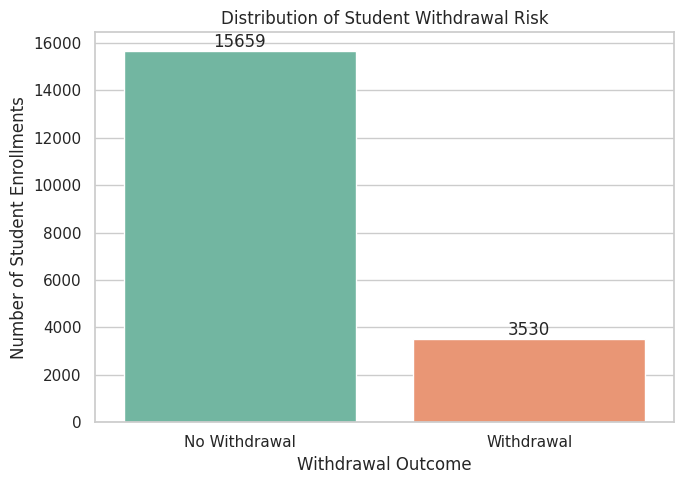

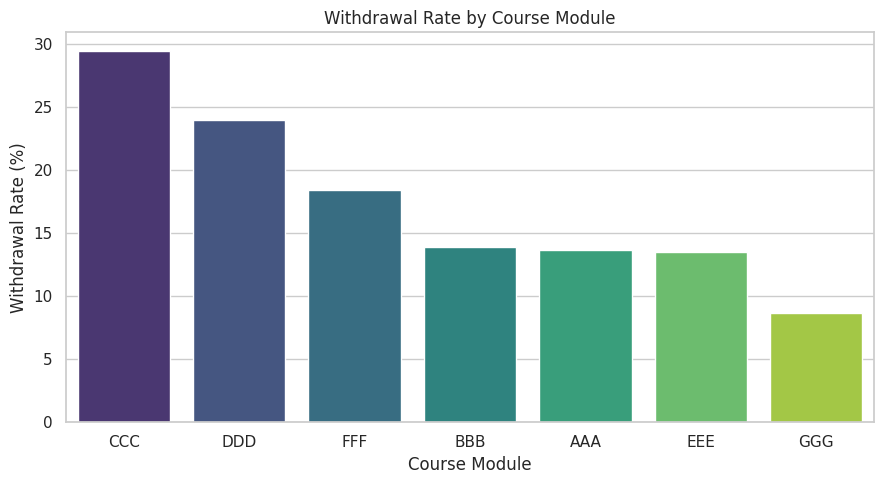

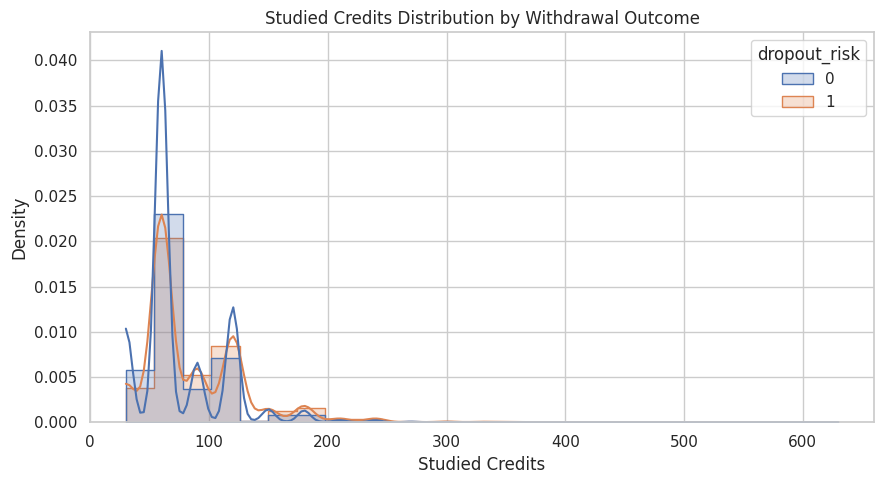

First 3 EDA plots generated successfully!


In [ ]:

# STEP 37: EDA - First 3 visualizations
# Use TRAINING DATA only to avoid test-set peeking

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

eda_train = X_train.copy()
eda_train["dropout_risk"] = y_train

# Plot 1: Class distribution
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=eda_train,
    x="dropout_risk",
    hue="dropout_risk",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Student Withdrawal Risk")
plt.xlabel("Withdrawal Outcome")
plt.ylabel("Number of Student Enrollments")
plt.xticks([0, 1], ["No Withdrawal", "Withdrawal"])

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()


# Plot 2: Withdrawal rate by course module
module_rates = (
    eda_train.groupby("code_module")["dropout_risk"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=module_rates.index,
    y=module_rates.values,
    hue=module_rates.index,
    palette="viridis",
    legend=False
)

plt.title("Withdrawal Rate by Course Module")
plt.xlabel("Course Module")
plt.ylabel("Withdrawal Rate (%)")

plt.tight_layout()
plt.show()


# Plot 3: Distribution of studied credits
plt.figure(figsize=(9, 5))

sns.histplot(
    data=eda_train,
    x="studied_credits",
    hue="dropout_risk",
    bins=25,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Studied Credits Distribution by Withdrawal Outcome")
plt.xlabel("Studied Credits")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

print("First 3 EDA plots generated successfully!")


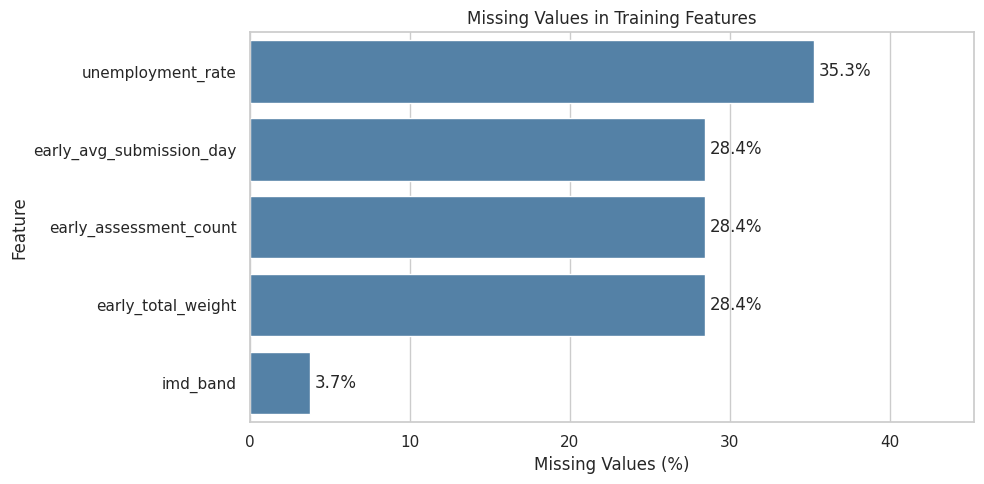

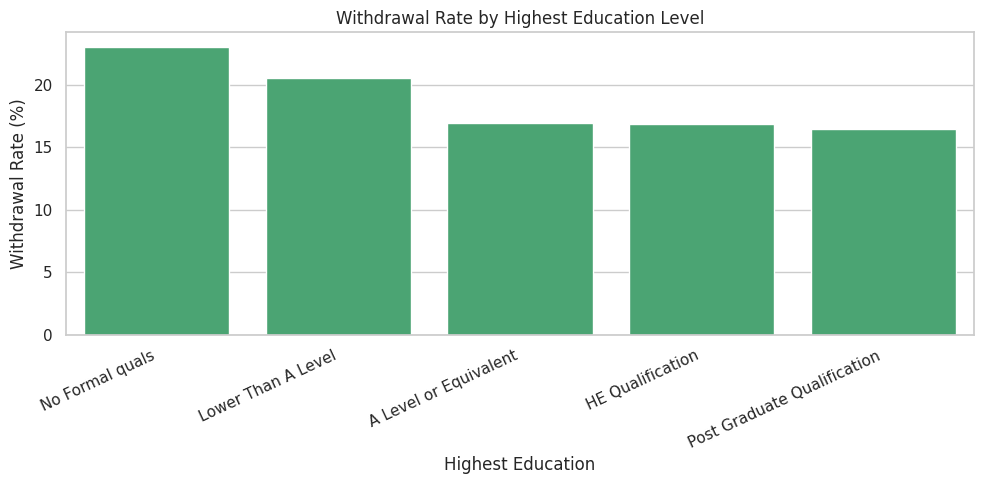

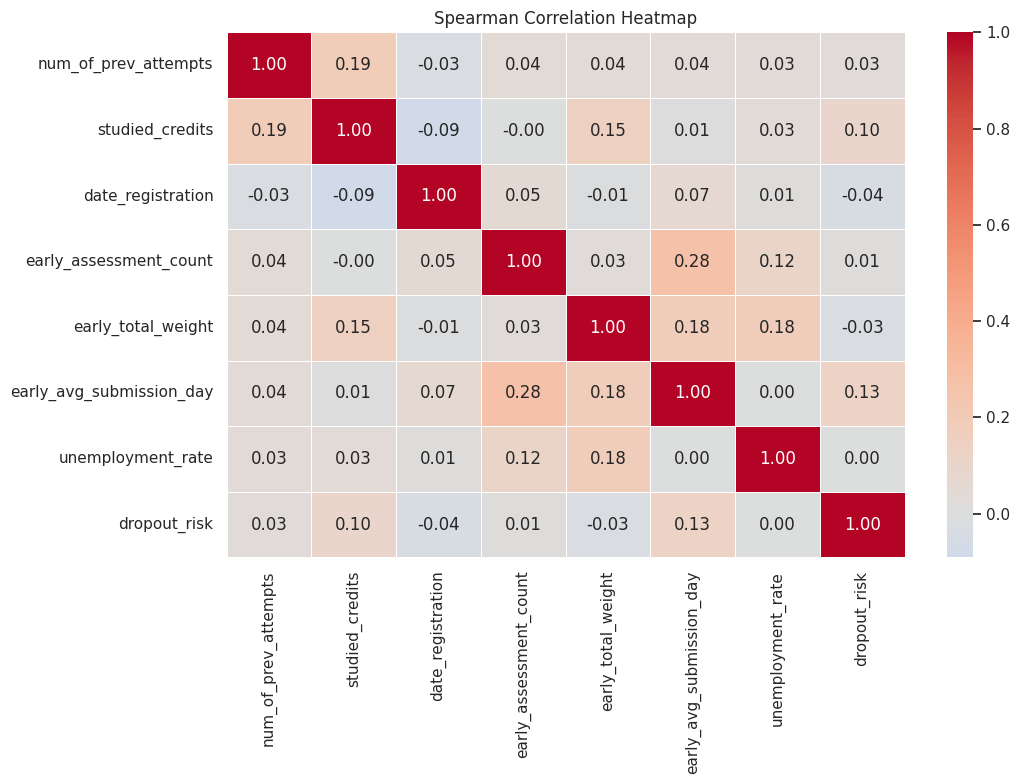

All 6 EDA plots generated successfully!


In [ ]:

# STEP 38: EDA - Remaining 3 visualizations

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Plot 4: Missing values in training features
missing_pct = (
    X_train.isna().mean() * 100
).sort_values(ascending=False)

missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=missing_pct.values,
    y=missing_pct.index,
    color="steelblue"
)

plt.title("Missing Values in Training Features")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")

for i, value in enumerate(missing_pct.values):
    ax.text(value + 0.3, i, f"{value:.1f}%", va="center")

plt.xlim(0, max(missing_pct.values) + 10)
plt.tight_layout()
plt.show()


# Plot 5: Withdrawal rate by education level
education_rates = (
    eda_train.groupby("highest_education")["dropout_risk"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

education_rates["withdrawal_pct"] = (
    education_rates["mean"] * 100
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=education_rates.reset_index(),
    x="highest_education",
    y="withdrawal_pct",
    color="mediumseagreen"
)

plt.title("Withdrawal Rate by Highest Education Level")
plt.xlabel("Highest Education")
plt.ylabel("Withdrawal Rate (%)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()


# Plot 6: Correlation heatmap of numerical features
numerical_eda = eda_train[
    numerical_features + ["dropout_risk"]
].copy()

correlation_matrix = numerical_eda.corr(
    method="spearman"
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

print("All 6 EDA plots generated successfully!")


In [ ]:

# STEP 39: Numerical outlier analysis using IQR
# Training data only

import pandas as pd

outlier_results = []

for feature in numerical_features:

    values = X_train[feature].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    outlier_percentage = (
        outlier_count / len(values) * 100
        if len(values) > 0 else 0
    )

    outlier_results.append({
        "Feature": feature,
        "Minimum": values.min(),
        "Q1": q1,
        "Median": values.median(),
        "Q3": q3,
        "Maximum": values.max(),
        "IQR": iqr,
        "Outliers": outlier_count,
        "Outlier %": round(outlier_percentage, 2)
    })

outlier_summary = pd.DataFrame(outlier_results)

print("=" * 60)
print("NUMERICAL OUTLIER ANALYSIS")
print("=" * 60)

display(outlier_summary)

print("\nTotal numerical features analyzed:",
      len(outlier_summary))

print("\nOutlier analysis completed!")


NUMERICAL OUTLIER ANALYSIS


,Feature,Minimum,Q1,Median,Q3,Maximum,IQR,Outliers,Outlier %
0,num_of_prev_attempts,0.000000,0.000000,0.000000,0.00000,6.000000,0.000000,2416,12.59
1,studied_credits,30.000000,60.000000,60.000000,90.00000,630.000000,30.000000,1048,5.46
2,date_registration,-311.000000,-95.000000,-53.000000,-29.00000,28.000000,66.000000,252,1.31
3,early_assessment_count,1.000000,1.000000,1.000000,1.00000,2.000000,0.000000,629,4.58
4,early_total_weight,0.000000,5.000000,5.000000,12.50000,12.500000,7.500000,0,0.00
5,early_avg_submission_day,0.000000,17.000000,19.000000,22.00000,30.000000,5.000000,633,4.61
6,unemployment_rate,4.364713,6.295698,7.301637,8.13484,9.818718,1.839142,0,0.00



Total numerical features analyzed: 7

Outlier analysis completed!


In [ ]:

# STEP 40: Verify feature data types

print("=" * 55)
print("FEATURE DATA TYPES")
print("=" * 55)

print("\nCategorical features:")
print(X_train[categorical_features].dtypes)

print("\nNumerical features:")
print(X_train[numerical_features].dtypes)

print("\nUnexpected numerical data types:")

invalid_numerical = [
    col for col in numerical_features
    if not pd.api.types.is_numeric_dtype(X_train[col])
]

print(invalid_numerical)

assert len(invalid_numerical) == 0, (
    "Some numerical features need conversion!"
)

print("\nAll numerical features have valid data types!")


FEATURE DATA TYPES

Categorical features:
code_module          object
code_presentation    object
gender               object
region               object
highest_education    object
imd_band             object
age_band             object
disability           object
dtype: object

Numerical features:
num_of_prev_attempts          int64
studied_credits               int64
date_registration           float64
early_assessment_count      float64
early_total_weight          float64
early_avg_submission_day    float64
unemployment_rate           float64
dtype: object

Unexpected numerical data types:
[]

All numerical features have valid data types!


In [ ]:

# STEP 41: Build preprocessing pipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("=" * 60)
print("ML PREPROCESSING PIPELINE")
print("=" * 60)

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical pipeline:")
print(numerical_pipeline)

print("\nCategorical pipeline:")
print(categorical_pipeline)

print("\nColumnTransformer created successfully!")

assert len(numerical_features) == 7
assert len(categorical_features) == 8
assert len(set(numerical_features + categorical_features)) == 15

print("\nAll preprocessing configuration checks passed!")


ML PREPROCESSING PIPELINE

Numerical features: 7
Categorical features: 8

Numerical pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

Categorical pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

ColumnTransformer created successfully!

All preprocessing configuration checks passed!


In [ ]:

# STEP 42: Train and evaluate baseline model

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Fit baseline using training data only
baseline_model.fit(X_train, y_train)

# Predict validation data
baseline_predictions = baseline_model.predict(X_val)

print("=" * 60)
print("BASELINE MODEL RESULTS - VALIDATION DATA")
print("=" * 60)

print("Accuracy:",
      round(accuracy_score(y_val, baseline_predictions), 4))

print("Precision:",
      round(precision_score(
          y_val, baseline_predictions,
          zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_val, baseline_predictions,
          zero_division=0
      ), 4))

print("F1 Score:",
      round(f1_score(
          y_val, baseline_predictions,
          zero_division=0
      ), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, baseline_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    baseline_predictions,
    target_names=["No Withdrawal", "Withdrawal"],
    zero_division=0
))

print("\nBaseline model evaluation completed!")


BASELINE MODEL RESULTS - VALIDATION DATA
Accuracy: 0.8136
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Confusion Matrix:
[[3365    0]
 [ 771    0]]

Classification Report:
               precision    recall  f1-score   support

No Withdrawal       0.81      1.00      0.90      3365
   Withdrawal       0.00      0.00      0.00       771

     accuracy                           0.81      4136
    macro avg       0.41      0.50      0.45      4136
 weighted avg       0.66      0.81      0.73      4136


Baseline model evaluation completed!


In [ ]:

# STEP 43: Train Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train on training data only
logistic_model.fit(X_train, y_train)

print("=" * 60)
print("LOGISTIC REGRESSION TRAINING")
print("=" * 60)

print("Training records:", len(X_train))
print("Input features:", X_train.shape[1])

print("\nLogistic Regression trained successfully!")


LOGISTIC REGRESSION TRAINING
Training records: 19189
Input features: 15

Logistic Regression trained successfully!


In [ ]:

# STEP 44: Evaluate Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

logistic_predictions = logistic_model.predict(X_val)
logistic_probabilities = logistic_model.predict_proba(X_val)[:, 1]

logistic_accuracy = accuracy_score(y_val, logistic_predictions)
logistic_precision = precision_score(
    y_val, logistic_predictions, zero_division=0
)
logistic_recall = recall_score(
    y_val, logistic_predictions, zero_division=0
)
logistic_f1 = f1_score(
    y_val, logistic_predictions, zero_division=0
)
logistic_roc_auc = roc_auc_score(
    y_val, logistic_probabilities
)

print("=" * 60)
print("LOGISTIC REGRESSION - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall:    {logistic_recall:.4f}")
print(f"F1 Score:  {logistic_f1:.4f}")
print(f"ROC-AUC:   {logistic_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, logistic_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    logistic_predictions,
    target_names=["No Withdrawal", "Withdrawal"],
    zero_division=0
))

print("\nLogistic Regression evaluation completed!")


LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy:  0.6257
Precision: 0.2816
Recall:    0.6498
F1 Score:  0.3929
ROC-AUC:   0.6740

Confusion Matrix:
[[2087 1278]
 [ 270  501]]

Classification Report:
               precision    recall  f1-score   support

No Withdrawal       0.89      0.62      0.73      3365
   Withdrawal       0.28      0.65      0.39       771

     accuracy                           0.63      4136
    macro avg       0.58      0.64      0.56      4136
 weighted avg       0.77      0.63      0.67      4136


Logistic Regression evaluation completed!


In [ ]:

# STEP 45: Train Random Forest model

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

random_forest_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("=" * 60)
print("RANDOM FOREST TRAINING")
print("=" * 60)

print("Training records:", len(X_train))
print("Input features:", X_train.shape[1])
print("Number of trees:", 200)

print("\nRandom Forest trained successfully!")


RANDOM FOREST TRAINING
Training records: 19189
Input features: 15
Number of trees: 200

Random Forest trained successfully!


In [ ]:

# STEP 46: Evaluate Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

rf_predictions = random_forest_model.predict(X_val)
rf_probabilities = random_forest_model.predict_proba(X_val)[:, 1]

rf_accuracy = accuracy_score(y_val, rf_predictions)
rf_precision = precision_score(
    y_val, rf_predictions, zero_division=0
)
rf_recall = recall_score(
    y_val, rf_predictions, zero_division=0
)
rf_f1 = f1_score(
    y_val, rf_predictions, zero_division=0
)
rf_roc_auc = roc_auc_score(
    y_val, rf_probabilities
)

print("=" * 60)
print("RANDOM FOREST - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_predictions,
    target_names=["No Withdrawal", "Withdrawal"],
    zero_division=0
))

print("\nRandom Forest evaluation completed!")


RANDOM FOREST - VALIDATION RESULTS
Accuracy:  0.7183
Precision: 0.3219
Recall:    0.4617
F1 Score:  0.3793
ROC-AUC:   0.6786

Confusion Matrix:
[[2615  750]
 [ 415  356]]

Classification Report:
               precision    recall  f1-score   support

No Withdrawal       0.86      0.78      0.82      3365
   Withdrawal       0.32      0.46      0.38       771

     accuracy                           0.72      4136
    macro avg       0.59      0.62      0.60      4136
 weighted avg       0.76      0.72      0.74      4136


Random Forest evaluation completed!


In [ ]:

# STEP 47: Compare initial ML models

import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_accuracy,
        "Precision": logistic_precision,
        "Recall": logistic_recall,
        "F1 Score": logistic_f1,
        "ROC-AUC": logistic_roc_auc
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1,
        "ROC-AUC": rf_roc_auc
    }
])

model_comparison = (
    model_comparison
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)

print("=" * 60)
print("INITIAL MODEL COMPARISON - VALIDATION DATA")
print("=" * 60)

display(model_comparison.round(4))

print("\nCurrent best model by F1 Score:")
print(model_comparison.loc[0, "Model"])


INITIAL MODEL COMPARISON - VALIDATION DATA


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6257,0.2816,0.6498,0.3929,0.6740
1,Random Forest,0.7183,0.3219,0.4617,0.3793,0.6786



Current best model by F1 Score:
Logistic Regression


In [ ]:

# STEP 48: Train K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

knn_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(
        n_neighbors=15,
        weights="distance",
        metric="minkowski",
        p=2,
        n_jobs=-1
    ))
])

knn_model.fit(X_train, y_train)

print("=" * 60)
print("KNN TRAINING")
print("=" * 60)

print("Training records:", len(X_train))
print("Input features:", X_train.shape[1])
print("Number of neighbors:", 15)

print("\nKNN trained successfully!")


KNN TRAINING
Training records: 19189
Input features: 15
Number of neighbors: 15

KNN trained successfully!


In [ ]:

# STEP 49: Evaluate KNN

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

knn_predictions = knn_model.predict(X_val)
knn_probabilities = knn_model.predict_proba(X_val)[:, 1]

knn_accuracy = accuracy_score(y_val, knn_predictions)
knn_precision = precision_score(
    y_val, knn_predictions, zero_division=0
)
knn_recall = recall_score(
    y_val, knn_predictions, zero_division=0
)
knn_f1 = f1_score(
    y_val, knn_predictions, zero_division=0
)
knn_roc_auc = roc_auc_score(
    y_val, knn_probabilities
)

print("=" * 60)
print("KNN - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy:  {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall:    {knn_recall:.4f}")
print(f"F1 Score:  {knn_f1:.4f}")
print(f"ROC-AUC:   {knn_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, knn_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    knn_predictions,
    target_names=["No Withdrawal", "Withdrawal"],
    zero_division=0
))

print("\nKNN evaluation completed!")


KNN - VALIDATION RESULTS
Accuracy:  0.8075
Precision: 0.3016
Recall:    0.0246
F1 Score:  0.0456
ROC-AUC:   0.6184

Confusion Matrix:
[[3321   44]
 [ 752   19]]

Classification Report:
               precision    recall  f1-score   support

No Withdrawal       0.82      0.99      0.89      3365
   Withdrawal       0.30      0.02      0.05       771

     accuracy                           0.81      4136
    macro avg       0.56      0.51      0.47      4136
 weighted avg       0.72      0.81      0.74      4136


KNN evaluation completed!


In [ ]:

# STEP 50: Compare all three ML algorithms

import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_accuracy,
        "Precision": logistic_precision,
        "Recall": logistic_recall,
        "F1 Score": logistic_f1,
        "ROC-AUC": logistic_roc_auc
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1,
        "ROC-AUC": rf_roc_auc
    },
    {
        "Model": "KNN",
        "Accuracy": knn_accuracy,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1 Score": knn_f1,
        "ROC-AUC": knn_roc_auc
    }
])

model_comparison = (
    model_comparison
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)

print("=" * 60)
print("THREE ML ALGORITHMS - VALIDATION COMPARISON")
print("=" * 60)

display(model_comparison.round(4))

print("\nCurrent best model by F1 Score:")
print(model_comparison.loc[0, "Model"])


THREE ML ALGORITHMS - VALIDATION COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6257,0.2816,0.6498,0.3929,0.6740
1,Random Forest,0.7183,0.3219,0.4617,0.3793,0.6786
2,KNN,0.8075,0.3016,0.0246,0.0456,0.6184



Current best model by F1 Score:
Logistic Regression


In [ ]:

# STEP 51: Configure group-aware 5-fold cross-validation

from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

train_groups = combined_data.loc[X_train.index, "id_student"]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_results = []

for fold, (train_fold_idx, valid_fold_idx) in enumerate(
    cv.split(X_train, y_train, groups=train_groups),
    start=1
):
    fold_train_groups = set(
        train_groups.iloc[train_fold_idx]
    )
    fold_valid_groups = set(
        train_groups.iloc[valid_fold_idx]
    )

    overlap = len(
        fold_train_groups.intersection(fold_valid_groups)
    )

    fold_results.append({
        "Fold": fold,
        "Training Records": len(train_fold_idx),
        "Validation Records": len(valid_fold_idx),
        "Training Withdrawal %": round(
            y_train.iloc[train_fold_idx].mean() * 100, 2
        ),
        "Validation Withdrawal %": round(
            y_train.iloc[valid_fold_idx].mean() * 100, 2
        ),
        "Student Overlap": overlap
    })

cv_summary = pd.DataFrame(fold_results)

print("=" * 60)
print("GROUP-AWARE 5-FOLD CROSS-VALIDATION SETUP")
print("=" * 60)

display(cv_summary)

assert (cv_summary["Student Overlap"] == 0).all()

print("\nAll 5 folds have zero student overlap!")
print("Cross-validation configuration successful!")


GROUP-AWARE 5-FOLD CROSS-VALIDATION SETUP


,Fold,Training Records,Validation Records,Training Withdrawal %,Validation Withdrawal %,Student Overlap
0,1,15344,3845,18.31,18.73,0
1,2,15327,3862,18.50,18.00,0
2,3,15383,3806,18.34,18.63,0
3,4,15330,3859,18.42,18.29,0
4,5,15372,3817,18.41,18.34,0



All 5 folds have zero student overlap!
Cross-validation configuration successful!


In [ ]:

# STEP 52: Logistic Regression GridSearchCV

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=42
    ))
])

logistic_param_grid = {
    "classifier__C": [0.01, 0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"]
}

logistic_grid_search = GridSearchCV(
    estimator=logistic_tuning_pipeline,
    param_grid=logistic_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

logistic_grid_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("=" * 60)
print("LOGISTIC REGRESSION - GRID SEARCH RESULTS")
print("=" * 60)

print("\nBest parameters:")
print(logistic_grid_search.best_params_)

print("\nBest mean CV F1 Score:")
print(round(logistic_grid_search.best_score_, 4))

print("\nTotal parameter combinations:",
      len(logistic_grid_search.cv_results_["params"]))

print("\nLogistic Regression tuning completed!")


Fitting 5 folds for each of 8 candidates, totalling 40 fits
LOGISTIC REGRESSION - GRID SEARCH RESULTS

Best parameters:
{'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}

Best mean CV F1 Score:
0.3717

Total parameter combinations: 8

Logistic Regression tuning completed!


In [ ]:

# STEP 53: Evaluate tuned Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Best model selected by 5-fold CV
tuned_logistic_model = logistic_grid_search.best_estimator_

# Predict on validation data only
tuned_lr_predictions = tuned_logistic_model.predict(X_val)
tuned_lr_probabilities = tuned_logistic_model.predict_proba(X_val)[:, 1]

tuned_lr_accuracy = accuracy_score(y_val, tuned_lr_predictions)
tuned_lr_precision = precision_score(
    y_val, tuned_lr_predictions, zero_division=0
)
tuned_lr_recall = recall_score(
    y_val, tuned_lr_predictions, zero_division=0
)
tuned_lr_f1 = f1_score(
    y_val, tuned_lr_predictions, zero_division=0
)
tuned_lr_roc_auc = roc_auc_score(
    y_val, tuned_lr_probabilities
)

print("=" * 60)
print("TUNED LOGISTIC REGRESSION - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy:  {tuned_lr_accuracy:.4f}")
print(f"Precision: {tuned_lr_precision:.4f}")
print(f"Recall:    {tuned_lr_recall:.4f}")
print(f"F1 Score:  {tuned_lr_f1:.4f}")
print(f"ROC-AUC:   {tuned_lr_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, tuned_lr_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    tuned_lr_predictions,
    target_names=["No Withdrawal", "Withdrawal"],
    zero_division=0
))

print("\nTuned Logistic Regression evaluation completed!")


TUNED LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy:  0.6204
Precision: 0.2752
Recall:    0.6342
F1 Score:  0.3838
ROC-AUC:   0.6701

Confusion Matrix:
[[2077 1288]
 [ 282  489]]

Classification Report:
               precision    recall  f1-score   support

No Withdrawal       0.88      0.62      0.73      3365
   Withdrawal       0.28      0.63      0.38       771

     accuracy                           0.62      4136
    macro avg       0.58      0.63      0.55      4136
 weighted avg       0.77      0.62      0.66      4136


Tuned Logistic Regression evaluation completed!


In [ ]:

# STEP 54: Random Forest hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

rf_param_distributions = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [10, 15, 20, None],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=8,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1,
    random_state=42,
    refit=True
)

rf_random_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("=" * 60)
print("RANDOM FOREST - TUNING RESULTS")
print("=" * 60)

print("\nBest parameters:")
print(rf_random_search.best_params_)

print("\nBest mean CV F1 Score:")
print(round(rf_random_search.best_score_, 4))

print("\nTotal parameter combinations tested:",
      len(rf_random_search.cv_results_["params"]))

print("\nRandom Forest tuning completed!")


Fitting 5 folds for each of 8 candidates, totalling 40 fits
RANDOM FOREST - TUNING RESULTS

Best parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced_subsample'}

Best mean CV F1 Score:
0.3725

Total parameter combinations tested: 8

Random Forest tuning completed!


In [ ]:

# STEP 55: Evaluate tuned Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

tuned_rf_model = rf_random_search.best_estimator_

tuned_rf_predictions = tuned_rf_model.predict(X_val)
tuned_rf_probabilities = tuned_rf_model.predict_proba(X_val)[:, 1]

tuned_rf_accuracy = accuracy_score(y_val, tuned_rf_predictions)
tuned_rf_precision = precision_score(
    y_val, tuned_rf_predictions, zero_division=0
)
tuned_rf_recall = recall_score(
    y_val, tuned_rf_predictions, zero_division=0
)
tuned_rf_f1 = f1_score(
    y_val, tuned_rf_predictions, zero_division=0
)
tuned_rf_roc_auc = roc_auc_score(
    y_val, tuned_rf_probabilities
)

print("=" * 60)
print("TUNED RANDOM FOREST - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy:  {tuned_rf_accuracy:.4f}")
print(f"Precision: {tuned_rf_precision:.4f}")
print(f"Recall:    {tuned_rf_recall:.4f}")
print(f"F1 Score:  {tuned_rf_f1:.4f}")
print(f"ROC-AUC:   {tuned_rf_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, tuned_rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    tuned_rf_predictions,
    target_names=["No Withdrawal", "Withdrawal"],
    zero_division=0
))

print("\nTuned Random Forest evaluation completed!")


TUNED RANDOM FOREST - VALIDATION RESULTS
Accuracy:  0.6666
Precision: 0.2971
Recall:    0.5772
F1 Score:  0.3922
ROC-AUC:   0.6828

Confusion Matrix:
[[2312 1053]
 [ 326  445]]

Classification Report:
               precision    recall  f1-score   support

No Withdrawal       0.88      0.69      0.77      3365
   Withdrawal       0.30      0.58      0.39       771

     accuracy                           0.67      4136
    macro avg       0.59      0.63      0.58      4136
 weighted avg       0.77      0.67      0.70      4136


Tuned Random Forest evaluation completed!


In [ ]:

# STEP 56: KNN hyperparameter tuning

from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

knn_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(
        n_jobs=1
    ))
])

knn_param_grid = {
    "classifier__n_neighbors": [5, 11, 21, 31],
    "classifier__weights": ["uniform", "distance"]
}

knn_grid_search = GridSearchCV(
    estimator=knn_tuning_pipeline,
    param_grid=knn_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1,
    refit=True
)

knn_grid_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("=" * 60)
print("KNN - TUNING RESULTS")
print("=" * 60)

print("\nBest parameters:")
print(knn_grid_search.best_params_)

print("\nBest mean CV F1 Score:")
print(round(knn_grid_search.best_score_, 4))

print("\nTotal combinations tested:",
      len(knn_grid_search.cv_results_["params"]))

print("\nKNN tuning completed!")


Fitting 5 folds for each of 8 candidates, totalling 40 fits
KNN - TUNING RESULTS

Best parameters:
{'classifier__n_neighbors': 5, 'classifier__weights': 'distance'}

Best mean CV F1 Score:
0.1431

Total combinations tested: 8

KNN tuning completed!


In [ ]:

# Check which project variables exist in Colab memory

required_variables = [
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "preprocessor",
    "cv",
    "train_groups",
    "knn_grid_search",
    "logistic_grid_search",
    "rf_random_search"
]

for variable in required_variables:
    status = "AVAILABLE" if variable in globals() else "MISSING"
    print(f"{variable}: {status}")


X_train: MISSING
y_train: MISSING
X_val: MISSING
y_val: MISSING
preprocessor: MISSING
cv: MISSING
train_groups: MISSING
knn_grid_search: MISSING
logistic_grid_search: MISSING
rf_random_search: MISSING


In [ ]:

import os

print("Current files in /content/:")
print(os.listdir("/content/"))


Current files in /content/:
['.config', 'sample_data']


In [ ]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully!")


Mounted at /content/drive
Google Drive mounted successfully!


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Student_Dropout_ML_Project"
)

DATA_DIR = PROJECT_DIR / "data"
MODELS_DIR = PROJECT_DIR / "models"

DATA_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Data folder:", DATA_DIR)
print("Models folder:", MODELS_DIR)
print("Project folders created successfully!")


Project folder: /content/drive/MyDrive/Student_Dropout_ML_Project
Data folder: /content/drive/MyDrive/Student_Dropout_ML_Project/data
Models folder: /content/drive/MyDrive/Student_Dropout_ML_Project/models
Project folders created successfully!


In [ ]:

from google.colab import files
from pathlib import Path

print("Upload your project dataset files:")

uploaded = files.upload()

for filename, content in uploaded.items():
    destination = DATA_DIR / filename
    destination.write_bytes(content)
    print(f"Saved permanently: {destination}")

print("\nAll uploaded files saved to Google Drive!")


Upload your project dataset files:


Saving unemployment-region.xlsx to unemployment-region.xlsx
Saving data.csv to data.csv
Saving assessments.csv to assessments (1).csv
Saving studentAssessment.csv to studentAssessment (1).csv
Saving studentInfo.csv to studentInfo (1).csv
Saving studentRegistration.csv to studentRegistration (1).csv
Saved permanently: /content/drive/MyDrive/Student_Dropout_ML_Project/data/unemployment-region.xlsx
Saved permanently: /content/drive/MyDrive/Student_Dropout_ML_Project/data/data.csv
Saved permanently: /content/drive/MyDrive/Student_Dropout_ML_Project/data/assessments (1).csv
Saved permanently: /content/drive/MyDrive/Student_Dropout_ML_Project/data/studentAssessment (1).csv
Saved permanently: /content/drive/MyDrive/Student_Dropout_ML_Project/data/studentInfo (1).csv
Saved permanently: /content/drive/MyDrive/Student_Dropout_ML_Project/data/studentRegistration (1).csv

All uploaded files saved to Google Drive!


In [ ]:

print("Files permanently saved in Google Drive:\n")

for file in sorted(DATA_DIR.iterdir()):
    if file.is_file():
        print(f"{file.name} ({file.stat().st_size / 1024 / 1024:.2f} MB)")


Files permanently saved in Google Drive:

assessments (1).csv (0.01 MB)
assessments.csv (0.01 MB)
data.csv (0.51 MB)
studentAssessment (1).csv (5.43 MB)
studentAssessment.csv (5.43 MB)
studentInfo (1).csv (3.30 MB)
studentInfo.csv (3.30 MB)
studentRegistration (1).csv (1.06 MB)
studentRegistration.csv (1.06 MB)
unemployment-region.xlsx (0.14 MB)


In [ ]:

# STEP 5: Restore datasets from permanent Google Drive storage

import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Student_Dropout_ML_Project/data"
)

student_info = pd.read_csv(DATA_DIR / "studentInfo.csv")
student_registration = pd.read_csv(
    DATA_DIR / "studentRegistration.csv"
)
assessments = pd.read_csv(DATA_DIR / "assessments.csv")
student_assessment = pd.read_csv(
    DATA_DIR / "studentAssessment.csv"
)
uci_data = pd.read_csv(DATA_DIR / "data.csv")

unemployment_filename = str(
    DATA_DIR / "unemployment-region.xlsx"
)

print("=" * 60)
print("DATASETS RESTORED FROM GOOGLE DRIVE")
print("=" * 60)

print("Student Info:", student_info.shape)
print("Student Registration:", student_registration.shape)
print("Assessments:", assessments.shape)
print("Student Assessment:", student_assessment.shape)
print("UCI Dataset:", uci_data.shape)

unemployment_raw = pd.read_excel(
    unemployment_filename,
    sheet_name="Unemployed",
    header=None
)

print("Unemployment Workbook:", unemployment_raw.shape)

print("\nAll original datasets restored successfully!")


DATASETS RESTORED FROM GOOGLE DRIVE
Student Info: (32593, 12)
Student Registration: (32593, 5)
Assessments: (206, 6)
Student Assessment: (173912, 5)
UCI Dataset: (4424, 1)
Unemployment Workbook: (32, 188)

All original datasets restored successfully!


In [ ]:

# STEP 6: Correct UCI dataset separator

uci_data = pd.read_csv(
    DATA_DIR / "data.csv",
    sep=";"
)

print("Corrected UCI Dataset Shape:", uci_data.shape)
print("\nFirst 5 column names:")
print(uci_data.columns[:5].tolist())

assert uci_data.shape == (4424, 37)

print("\nUCI dataset loaded correctly!")


Corrected UCI Dataset Shape: (4424, 37)

First 5 column names:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t']

UCI dataset loaded correctly!


In [ ]:

# STEP 7: RECOVER PROJECT DATA AND ML SPLITS

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Student_Dropout_ML_Project"
)
DATA_DIR = PROJECT_DIR / "data"
MODELS_DIR = PROJECT_DIR / "models"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Merge OULAD enrollment information
keys = ["code_module", "code_presentation", "id_student"]

merged_data = student_info.merge(
    student_registration,
    on=keys,
    how="left",
    validate="one_to_one"
)

# 2. Recreate first-30-day assessment features
assessment_records = student_assessment.merge(
    assessments,
    on="id_assessment",
    how="left",
    validate="many_to_one",
    indicator=True
)

assert (assessment_records["_merge"] == "both").all()

assessment_records = assessment_records.drop(
    columns="_merge"
)

early_assessments = assessment_records[
    (assessment_records["date_submitted"] >= 0) &
    (assessment_records["date_submitted"] <= 30) &
    (assessment_records["date"] <= 30) &
    (assessment_records["is_banked"] == 0)
].copy()

assessment_features = early_assessments.groupby(keys).agg(
    early_assessment_count=("id_assessment", "count"),
    early_avg_score=("score", "mean"),
    early_max_score=("score", "max"),
    early_min_score=("score", "min"),
    early_score_std=("score", "std"),
    early_total_weight=("weight", "sum"),
    early_avg_submission_day=("date_submitted", "mean")
).reset_index()

model_data = merged_data.merge(
    assessment_features,
    on=keys,
    how="left",
    validate="one_to_one"
)

# 3. Apply Day-30 eligibility rules
eligible_data = model_data[
    model_data["date_registration"].notna() &
    (model_data["date_registration"] <= 30)
].copy()

eligible_data = eligible_data[
    eligible_data["date_unregistration"].isna() |
    (eligible_data["date_unregistration"] > 30)
].copy()

eligible_data["dropout_risk"] = (
    eligible_data["final_result"] == "Withdrawn"
).astype(int)

# 4. Recreate unemployment lookup
unemployment_raw = pd.read_excel(
    DATA_DIR / "unemployment-region.xlsx",
    sheet_name="Unemployed",
    header=None
)

# Historical period dates in first row,
# regional rates in rows 18 through 31
rate_rows = unemployment_raw.iloc[18:32].copy()

history_records = []

for col in range(1, unemployment_raw.shape[1]):
    period = pd.to_datetime(
        unemployment_raw.iloc[0, col],
        errors="coerce"
    )

    if pd.isna(period):
        continue

    for row in range(18, 32):
        region = unemployment_raw.iloc[row, 0]
        rate = pd.to_numeric(
            unemployment_raw.iloc[row, col],
            errors="coerce"
        )

        if pd.notna(region) and pd.notna(rate):
            history_records.append({
                "ons_region": str(region).strip(),
                "period": period,
                "unemployment_rate": float(rate)
            })

unemployment_history = pd.DataFrame(history_records)

reference_dates = {
    "2013B": "2012-10-01",
    "2013J": "2013-06-01",
    "2014B": "2013-10-01",
    "2014J": "2014-06-01"
}

lookup_parts = []

for presentation, reference_date in reference_dates.items():
    target_period = pd.Timestamp(reference_date)

    selected = unemployment_history[
        unemployment_history["period"].dt.to_period("M")
        == target_period.to_period("M")
    ].copy()

    selected["code_presentation"] = presentation
    selected["reference_period"] = reference_date

    lookup_parts.append(selected)

unemployment_lookup = pd.concat(
    lookup_parts,
    ignore_index=True
)

safe_region_mapping = {
    "Scotland": "Scotland",
    "London Region": "London",
    "North Western Region": "North West",
    "West Midlands Region": "West Midlands",
    "South West Region": "South West",
    "East Midlands Region": "East Midlands",
    "Wales": "Wales",
    "South East Region": "South East"
}

combined_data = eligible_data.copy()

combined_data["ons_region"] = (
    combined_data["region"].map(safe_region_mapping)
)

combined_data = combined_data.merge(
    unemployment_lookup[
        [
            "ons_region",
            "code_presentation",
            "unemployment_rate",
            "reference_period"
        ]
    ],
    on=["ons_region", "code_presentation"],
    how="left",
    validate="many_to_one"
)

# 5. Restore 15 input features
categorical_features = [
    "code_module",
    "code_presentation",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

numerical_features = [
    "num_of_prev_attempts",
    "studied_credits",
    "date_registration",
    "early_assessment_count",
    "early_total_weight",
    "early_avg_submission_day",
    "unemployment_rate"
]

selected_features = (
    categorical_features + numerical_features
)

X = combined_data[selected_features].copy()
y = combined_data["dropout_risk"].copy()
groups = combined_data["id_student"]

# 6. Restore original group-safe splits
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()

X_temp = X.iloc[temp_idx].copy()
y_temp = y.iloc[temp_idx].copy()
groups_temp = groups.iloc[temp_idx]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_rel_idx, test_rel_idx = next(
    split2.split(X_temp, y_temp, groups=groups_temp)
)

X_val = X_temp.iloc[val_rel_idx].copy()
y_val = y_temp.iloc[val_rel_idx].copy()

X_test = X_temp.iloc[test_rel_idx].copy()
y_test = y_temp.iloc[test_rel_idx].copy()

train_groups = groups.iloc[train_idx].copy()

# 7. Restore preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 8. Verify recovery before saving
assert len(combined_data) == 27443
assert X.shape[1] == 15
assert len(X_train) == 19189
assert len(X_val) == 4136
assert len(X_test) == 4118
assert combined_data[keys].duplicated().sum() == 0

train_ids = set(groups.iloc[train_idx])
val_ids = set(groups_temp.iloc[val_rel_idx])
test_ids = set(groups_temp.iloc[test_rel_idx])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# 9. Save processed data and split indices
combined_data.to_csv(
    DATA_DIR / "combined_day30_dataset.csv",
    index=False
)

np.savez(
    DATA_DIR / "split_indices.npz",
    train_idx=train_idx,
    temp_idx=temp_idx,
    val_rel_idx=val_rel_idx,
    test_rel_idx=test_rel_idx
)

print("=" * 60)
print("PROJECT DATA RECOVERY")
print("=" * 60)

print("Combined dataset:", combined_data.shape)
print("Unemployment matched:",
      combined_data["unemployment_rate"].notna().sum())

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("Student overlap: NONE")
print("Processed dataset saved to Google Drive")
print("Split indices saved to Google Drive")

print("\nDATA RECOVERY COMPLETED SUCCESSFULLY!")


PROJECT DATA RECOVERY
Combined dataset: (27443, 25)
Unemployment matched: 17750
Training: (19189, 15)
Validation: (4136, 15)
Testing: (4118, 15)
Student overlap: NONE
Processed dataset saved to Google Drive
Split indices saved to Google Drive

DATA RECOVERY COMPLETED SUCCESSFULLY!


In [ ]:

# STEP 8: Restore and permanently save tuned ML models

import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Best Logistic Regression from previous GridSearchCV
tuned_logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        C=0.01,
        class_weight="balanced",
        max_iter=2000,
        solver="lbfgs",
        random_state=42
    ))
])

# Best Random Forest from previous RandomizedSearchCV
tuned_rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Best KNN from previous GridSearchCV
tuned_knn_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ))
])

models_to_restore = {
    "tuned_logistic_regression": tuned_logistic_model,
    "tuned_random_forest": tuned_rf_model,
    "tuned_knn": tuned_knn_model
}

print("=" * 60)
print("RESTORING AND SAVING TUNED ML MODELS")
print("=" * 60)

for model_name, model in models_to_restore.items():

    print(f"\nTraining {model_name}...")

    model.fit(X_train, y_train)

    model_path = MODELS_DIR / f"{model_name}.joblib"
    joblib.dump(model, model_path)

    print(f"Saved: {model_path}")

print("\nAll 3 tuned models restored and saved successfully!")


RESTORING AND SAVING TUNED ML MODELS

Training tuned_logistic_regression...
Saved: /content/drive/MyDrive/Student_Dropout_ML_Project/models/tuned_logistic_regression.joblib

Training tuned_random_forest...
Saved: /content/drive/MyDrive/Student_Dropout_ML_Project/models/tuned_random_forest.joblib

Training tuned_knn...
Saved: /content/drive/MyDrive/Student_Dropout_ML_Project/models/tuned_knn.joblib

All 3 tuned models restored and saved successfully!


In [ ]:

# STEP 9: Verify saved model files

import joblib

print("=" * 60)
print("SAVED ML MODEL VERIFICATION")
print("=" * 60)

for model_name in models_to_restore:

    model_path = MODELS_DIR / f"{model_name}.joblib"

    assert model_path.exists(), f"Missing: {model_path}"

    loaded_model = joblib.load(model_path)

    sample_predictions = loaded_model.predict(
        X_val.iloc[:5]
    )

    print(f"\nModel: {model_name}")
    print("File exists: YES")
    print("Sample predictions:", sample_predictions.tolist())
    print(
        "File size:",
        round(model_path.stat().st_size / (1024 * 1024), 2),
        "MB"
    )

print("\nAll saved models loaded and verified successfully!")


SAVED ML MODEL VERIFICATION

Model: tuned_logistic_regression
File exists: YES
Sample predictions: [0, 0, 0, 0, 0]
File size: 0.01 MB

Model: tuned_random_forest
File exists: YES
Sample predictions: [0, 0, 0, 0, 0]
File size: 7.91 MB

Model: tuned_knn
File exists: YES
Sample predictions: [0, 0, 0, 0, 0]
File size: 7.91 MB

All saved models loaded and verified successfully!


In [ ]:

# STEP 57: Evaluate Tuned KNN on Validation Data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

knn_val_pred = tuned_knn_model.predict(X_val)
knn_val_prob = tuned_knn_model.predict_proba(X_val)[:, 1]

tuned_knn_accuracy = accuracy_score(y_val, knn_val_pred)
tuned_knn_precision = precision_score(
    y_val, knn_val_pred, zero_division=0
)
tuned_knn_recall = recall_score(
    y_val, knn_val_pred, zero_division=0
)
tuned_knn_f1 = f1_score(
    y_val, knn_val_pred, zero_division=0
)
tuned_knn_roc_auc = roc_auc_score(y_val, knn_val_prob)

print("=" * 55)
print("TUNED KNN - VALIDATION PERFORMANCE")
print("=" * 55)

print(f"Accuracy : {tuned_knn_accuracy:.4f}")
print(f"Precision: {tuned_knn_precision:.4f}")
print(f"Recall   : {tuned_knn_recall:.4f}")
print(f"F1-Score : {tuned_knn_f1:.4f}")
print(f"ROC-AUC  : {tuned_knn_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, knn_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val, knn_val_pred,
    target_names=["Not Withdrawn", "Withdrawn"],
    zero_division=0
))


TUNED KNN - VALIDATION PERFORMANCE
Accuracy : 0.7860
Precision: 0.2841
Recall   : 0.0973
F1-Score : 0.1449
ROC-AUC  : 0.5690

Confusion Matrix:
[[3176  189]
 [ 696   75]]

Classification Report:
               precision    recall  f1-score   support

Not Withdrawn       0.82      0.94      0.88      3365
    Withdrawn       0.28      0.10      0.14       771

     accuracy                           0.79      4136
    macro avg       0.55      0.52      0.51      4136
 weighted avg       0.72      0.79      0.74      4136



In [ ]:

# STEP 58: Compare All Three Tuned Models

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": tuned_logistic_model,
    "Random Forest": tuned_rf_model,
    "KNN": tuned_knn_model
}

comparison_results = []

for model_name, model in models.items():

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("=" * 65)
print("TUNED MODEL COMPARISON - VALIDATION DATA")
print("=" * 65)

print(comparison_df.round(4).to_string(index=False))

best_model_name = comparison_df.iloc[0]["Model"]

print("\nBest Model Based on Validation F1-Score:")
print(best_model_name)

comparison_df.to_csv(
    DATA_DIR / "tuned_model_comparison.csv",
    index=False
)

print("\nComparison results saved permanently to Google Drive!")


TUNED MODEL COMPARISON - VALIDATION DATA
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
      Random Forest    0.6666     0.2971  0.5772    0.3922   0.6828
Logistic Regression    0.6204     0.2752  0.6342    0.3838   0.6701
                KNN    0.7860     0.2841  0.0973    0.1449   0.5690

Best Model Based on Validation F1-Score:
Random Forest

Comparison results saved permanently to Google Drive!


In [ ]:

# STEP 59: Optimize Random Forest Threshold on Validation Data

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

rf_val_probabilities = tuned_rf_model.predict_proba(
    X_val
)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.01):

    predictions = (
        rf_val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df = threshold_df.sort_values(
    by=["F1-Score", "Threshold"],
    ascending=[False, True]
).reset_index(drop=True)

best_threshold = float(
    threshold_df.iloc[0]["Threshold"]
)

print("=" * 65)
print("RANDOM FOREST THRESHOLD OPTIMIZATION")
print("=" * 65)

print("\nTop 10 Thresholds:")
print(
    threshold_df.head(10)
    .round(4)
    .to_string(index=False)
)

print("\nBest Threshold:", best_threshold)

print(
    "Best Validation F1-Score:",
    round(float(threshold_df.iloc[0]["F1-Score"]), 4)
)

# Save optimization results permanently
threshold_df.to_csv(
    DATA_DIR / "random_forest_threshold_results.csv",
    index=False
)

print("\nThreshold results saved to Google Drive!")


RANDOM FOREST THRESHOLD OPTIMIZATION

Top 10 Thresholds:
 Threshold  Accuracy  Precision  Recall  F1-Score
      0.51    0.6859     0.3081  0.5499    0.3950
      0.48    0.6267     0.2818  0.6472    0.3926
      0.50    0.6666     0.2971  0.5772    0.3922
      0.52    0.6995     0.3121  0.5084    0.3868
      0.47    0.6032     0.2713  0.6693    0.3861
      0.49    0.6426     0.2838  0.6018    0.3857
      0.53    0.7149     0.3217  0.4773    0.3843
      0.45    0.5658     0.2595  0.7173    0.3811
      0.46    0.5820     0.2629  0.6887    0.3805
      0.54    0.7299     0.3307  0.4384    0.3770

Best Threshold: 0.51
Best Validation F1-Score: 0.395

Threshold results saved to Google Drive!


In [ ]:

# STEP 60: Final Held-Out Test Evaluation

import numpy as np
import pandas as pd
import json

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Selected model and validation-optimized threshold
final_model = tuned_rf_model
final_threshold = float(best_threshold)

assert 0 < final_threshold < 1
assert len(X_test) == len(y_test)

# Predict probabilities on untouched test data
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply previously selected threshold
test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, test_predictions)
test_precision = precision_score(
    y_test, test_predictions, zero_division=0
)
test_recall = recall_score(
    y_test, test_predictions, zero_division=0
)
test_f1 = f1_score(
    y_test, test_predictions, zero_division=0
)
test_roc_auc = roc_auc_score(
    y_test, test_probabilities
)

cm = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("=" * 65)
print("FINAL RANDOM FOREST - HELD-OUT TEST PERFORMANCE")
print("=" * 65)

print("Model: Tuned Random Forest")
print(f"Threshold: {final_threshold:.2f}")
print(f"Test Samples: {len(X_test)}")

print(f"\nAccuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-Score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nConfusion Matrix Breakdown:")
print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Not Withdrawn", "Withdrawn"],
    zero_division=0
))

# Save final metrics permanently
final_metrics = {
    "model": "Tuned Random Forest",
    "threshold": final_threshold,
    "test_samples": int(len(X_test)),
    "accuracy": float(test_accuracy),
    "precision": float(test_precision),
    "recall": float(test_recall),
    "f1_score": float(test_f1),
    "roc_auc": float(test_roc_auc),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp)
}

with open(
    MODELS_DIR / "final_test_metrics.json",
    "w"
) as f:
    json.dump(final_metrics, f, indent=4)

print("\nFinal test metrics saved to Google Drive!")


FINAL RANDOM FOREST - HELD-OUT TEST PERFORMANCE
Model: Tuned Random Forest
Threshold: 0.51
Test Samples: 4118

Accuracy : 0.6872
Precision: 0.2884
Recall   : 0.5178
F1-Score : 0.3705
ROC-AUC  : 0.6733

Confusion Matrix:
[[2451  935]
 [ 353  379]]

Confusion Matrix Breakdown:
True Negatives : 2451
False Positives: 935
False Negatives: 353
True Positives : 379

Classification Report:
               precision    recall  f1-score   support

Not Withdrawn       0.87      0.72      0.79      3386
    Withdrawn       0.29      0.52      0.37       732

     accuracy                           0.69      4118
    macro avg       0.58      0.62      0.58      4118
 weighted avg       0.77      0.69      0.72      4118


Final test metrics saved to Google Drive!


In [ ]:

# STEP 61: Create final deployment package

import json
import sys
import shutil
import sklearn
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

DEPLOY_DIR = PROJECT_DIR / "deployment"
DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

# Copy the selected trained model
source_model = MODELS_DIR / "tuned_random_forest.joblib"
destination_model = DEPLOY_DIR / "model.joblib"

assert source_model.exists(), "Trained Random Forest model not found!"

shutil.copy2(source_model, destination_model)

# Save model configuration
model_config = {
    "project_name": "Student Academic Performance & Dropout Risk Prediction",
    "prediction_task": "Course withdrawal after Day 30",
    "model": "Random Forest",
    "threshold": float(final_threshold),
    "positive_class": "Withdrawn",
    "negative_class": "Not Withdrawn",
    "prediction_day": 30,
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "selected_features": selected_features,
    "limitations": [
        "Predicts course withdrawal, not university degree dropout.",
        "Trained on historical OULAD data.",
        "Unemployment feature is unavailable for some regions.",
        "Predictions must not be used as automatic academic decisions."
    ]
}

config_path = DEPLOY_DIR / "model_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=4)

# Save exact package versions from current runtime
versions = {
    "python": sys.version.split()[0],
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "joblib": joblib.__version__
}

versions_path = DEPLOY_DIR / "package_versions.json"

with open(versions_path, "w", encoding="utf-8") as f:
    json.dump(versions, f, indent=4)

# Verify model can be loaded and used
loaded_model = joblib.load(destination_model)

assert list(loaded_model.feature_names_in_) == selected_features

sample_input = X_val.iloc[[0]][selected_features]
sample_probability = loaded_model.predict_proba(sample_input)[0, 1]

print("=" * 60)
print("FINAL MODEL DEPLOYMENT PACKAGE")
print("=" * 60)

print("\nModel:", destination_model)
print("Configuration:", config_path)
print("Versions:", versions_path)

print("\nSelected threshold:", model_config["threshold"])
print("Number of features:", len(selected_features))
print("Python version:", versions["python"])
print("Scikit-learn version:", versions["scikit-learn"])

print("\nSample prediction probability:",
      round(float(sample_probability), 4))

print("\nFiles in deployment folder:")
for file in sorted(DEPLOY_DIR.iterdir()):
    print("-", file.name)

print("\nDEPLOYMENT PACKAGE CREATED SUCCESSFULLY!")


FINAL MODEL DEPLOYMENT PACKAGE

Model: /content/drive/MyDrive/Student_Dropout_ML_Project/deployment/model.joblib
Configuration: /content/drive/MyDrive/Student_Dropout_ML_Project/deployment/model_config.json
Versions: /content/drive/MyDrive/Student_Dropout_ML_Project/deployment/package_versions.json

Selected threshold: 0.51
Number of features: 15
Python version: 3.13.18
Scikit-learn version: 1.6.1

Sample prediction probability: 0.3753

Files in deployment folder:
- model.joblib
- model_config.json
- package_versions.json

DEPLOYMENT PACKAGE CREATED SUCCESSFULLY!


In [ ]:

# STEP 62: CORRECTED Streamlit Deployment Data Preparation

import json
import pandas as pd

# Keep only the 8 regions used in our safe mapping
allowed_regions = set(safe_region_mapping.values())

deployment_lookup = unemployment_lookup[
    unemployment_lookup["ons_region"].isin(allowed_regions)
][
    [
        "code_presentation",
        "ons_region",
        "unemployment_rate"
    ]
].copy()

deployment_lookup = deployment_lookup.dropna(
    subset=[
        "code_presentation",
        "ons_region",
        "unemployment_rate"
    ]
)

deployment_lookup = deployment_lookup.drop_duplicates(
    subset=["code_presentation", "ons_region"]
)

# Validate lookup
assert len(deployment_lookup) == 32, (
    f"Expected 32 rows, got {len(deployment_lookup)}"
)

assert not deployment_lookup.duplicated(
    ["code_presentation", "ons_region"]
).any()

# Save historical unemployment lookup
lookup_path = DEPLOY_DIR / "unemployment_lookup.csv"

deployment_lookup.to_csv(
    lookup_path,
    index=False
)

# Save safe OULAD-to-ONS region mapping
region_mapping_path = DEPLOY_DIR / "region_mapping.json"

with open(region_mapping_path, "w", encoding="utf-8") as f:
    json.dump(safe_region_mapping, f, indent=4)

# Save categorical feature options
category_options = {}

for column in categorical_features:
    category_options[column] = sorted(
        X_train[column].dropna().astype(str).unique().tolist()
    )

category_options_path = DEPLOY_DIR / "category_options.json"

with open(category_options_path, "w", encoding="utf-8") as f:
    json.dump(category_options, f, indent=4)

# Verify lookup values match the training dataset
check = combined_data[
    ["code_presentation", "ons_region", "unemployment_rate"]
].dropna().drop_duplicates()

verified = check.merge(
    deployment_lookup,
    on=["code_presentation", "ons_region"],
    how="left",
    suffixes=("_original", "_deployment"),
    validate="many_to_one"
)

assert verified["unemployment_rate_deployment"].notna().all()

assert (
    verified["unemployment_rate_original"].round(8)
    ==
    verified["unemployment_rate_deployment"].round(8)
).all(), "Lookup values do not match!"

print("=" * 60)
print("STREAMLIT DEPLOYMENT DATA PREPARATION")
print("=" * 60)

print("\nUnemployment lookup rows:", len(deployment_lookup))
print(
    "Available presentations:",
    deployment_lookup["code_presentation"].nunique()
)
print(
    "Mapped regions:",
    deployment_lookup["ons_region"].nunique()
)

print("\nCategorical feature options:")
for feature, options in category_options.items():
    print(f"{feature}: {len(options)} options")

print("\nSaved deployment files:")
for file in sorted(DEPLOY_DIR.iterdir()):
    print("-", file.name)

print("\nSTEP 62 COMPLETED SUCCESSFULLY!")


STREAMLIT DEPLOYMENT DATA PREPARATION

Unemployment lookup rows: 32
Available presentations: 4
Mapped regions: 8

Categorical feature options:
code_module: 7 options
code_presentation: 4 options
gender: 2 options
region: 13 options
highest_education: 5 options
imd_band: 10 options
age_band: 3 options
disability: 2 options

Saved deployment files:
- category_options.json
- model.joblib
- model_config.json
- package_versions.json
- region_mapping.json
- unemployment_lookup.csv

STEP 62 COMPLETED SUCCESSFULLY!


In [ ]:

# STEP 63: Generate Streamlit Application

from pathlib import Path

app_code = r'''
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import streamlit as st

BASE_DIR = Path(__file__).resolve().parent

st.set_page_config(
    page_title="Student Withdrawal Risk Predictor",
    page_icon="🎓",
    layout="wide"
)

@st.cache_resource
def load_model():
    return joblib.load(BASE_DIR / "model.joblib")

@st.cache_data
def load_resources():
    with open(BASE_DIR / "model_config.json", encoding="utf-8") as f:
        config = json.load(f)

    with open(BASE_DIR / "category_options.json", encoding="utf-8") as f:
        options = json.load(f)

    with open(BASE_DIR / "region_mapping.json", encoding="utf-8") as f:
        region_mapping = json.load(f)

    unemployment = pd.read_csv(
        BASE_DIR / "unemployment_lookup.csv"
    )

    return config, options, region_mapping, unemployment

model = load_model()
config, options, region_mapping, unemployment = load_resources()

st.title("Student Academic Performance & Withdrawal Risk Prediction")
st.write(
    "An educational machine learning application that estimates "
    "the probability of course withdrawal after Day 30."
)

st.info(
    "This model predicts course withdrawal risk, not permanent "
    "university dropout. It is intended for educational demonstration "
    "and should not be used for automatic academic decisions."
)

st.subheader("Student Information")

with st.form("student_form"):

    col1, col2 = st.columns(2)

    with col1:
        code_module = st.selectbox(
            "Course Module",
            options["code_module"]
        )

        code_presentation = st.selectbox(
            "Course Presentation",
            options["code_presentation"]
        )

        gender = st.selectbox(
            "Gender",
            options["gender"]
        )

        region = st.selectbox(
            "Region",
            options["region"]
        )

        highest_education = st.selectbox(
            "Highest Education",
            options["highest_education"]
        )

        imd_band = st.selectbox(
            "IMD Band",
            options["imd_band"]
        )

        age_band = st.selectbox(
            "Age Band",
            options["age_band"]
        )

        disability = st.selectbox(
            "Disability",
            options["disability"]
        )

    with col2:
        num_of_prev_attempts = st.number_input(
            "Previous Attempts",
            min_value=0,
            max_value=20,
            value=0,
            step=1
        )

        studied_credits = st.number_input(
            "Studied Credits",
            min_value=0,
            max_value=630,
            value=60,
            step=10
        )

        date_registration = st.number_input(
            "Registration Day (relative to course start)",
            min_value=-400,
            max_value=30,
            value=-30,
            step=1
        )

        st.markdown("**First 30 Days: Assessment Activity**")

        early_assessment_count = st.number_input(
            "Assessments Submitted",
            min_value=0,
            max_value=30,
            value=0,
            step=1
        )

        early_total_weight = st.number_input(
            "Total Assessment Weight",
            min_value=0.0,
            max_value=200.0,
            value=0.0,
            step=1.0
        )

        early_avg_submission_day = st.number_input(
            "Average Submission Day",
            min_value=0.0,
            max_value=30.0,
            value=0.0,
            step=1.0
        )

    submitted = st.form_submit_button(
        "Predict Withdrawal Risk",
        use_container_width=True
    )

if submitted:

    ons_region = region_mapping.get(region)

    unemployment_rate = np.nan

    if ons_region is not None:

        matched = unemployment[
            (unemployment["code_presentation"] == code_presentation) &
            (unemployment["ons_region"] == ons_region)
        ]

        if not matched.empty:
            unemployment_rate = float(
                matched.iloc[0]["unemployment_rate"]
            )

    input_data = pd.DataFrame([{
        "code_module": code_module,
        "code_presentation": code_presentation,
        "gender": gender,
        "region": region,
        "highest_education": highest_education,
        "imd_band": imd_band,
        "age_band": age_band,
        "disability": disability,
        "num_of_prev_attempts": num_of_prev_attempts,
        "studied_credits": studied_credits,
        "date_registration": date_registration,
        "early_assessment_count": early_assessment_count,
        "early_total_weight": early_total_weight,
        "early_avg_submission_day": early_avg_submission_day,
        "unemployment_rate": unemployment_rate
    }])

    input_data = input_data[config["selected_features"]]

    risk_probability = float(
        model.predict_proba(input_data)[0, 1]
    )

    threshold = float(config["threshold"])
    at_risk = risk_probability >= threshold

    st.divider()
    st.subheader("Prediction Result")

    left, right = st.columns(2)

    with left:
        st.metric(
            "Estimated Withdrawal Probability",
            f"{risk_probability * 100:.2f}%"
        )

    with right:
        st.metric(
            "Decision Threshold",
            f"{threshold * 100:.0f}%"
        )

    if at_risk:
        st.warning(
            "⚠️ Higher predicted course withdrawal risk "
            "based on the selected threshold."
        )
    else:
        st.success(
            "Lower predicted course withdrawal risk "
            "based on the selected threshold."
        )

    st.subheader("Prediction Probability Chart")

    chart_data = pd.DataFrame({
        "Outcome": ["Not Withdrawn", "Withdrawn"],
        "Probability": [
            1 - risk_probability,
            risk_probability
        ]
    }).set_index("Outcome")

    st.bar_chart(chart_data)

    st.subheader("External Data Information")

    if pd.isna(unemployment_rate):
        st.write(
            "No reliable historical unemployment rate mapping "
            "was available for the selected region. The model "
            "used its training-data imputation procedure."
        )
    else:
        st.write(
            f"Historical regional unemployment rate: "
            f"{unemployment_rate:.2f}%"
        )

    st.caption(
        "Predictions are statistical estimates, not confirmed outcomes. "
        "The model was evaluated on historical OULAD records and may "
        "not generalize to other universities or student populations."
    )

st.divider()
st.caption(
    "Machine Learning CCP Project | "
    "Student Academic Performance & Dropout Risk Prediction"
)
'''

app_path = DEPLOY_DIR / "app.py"

app_path.write_text(app_code, encoding="utf-8")

print("=" * 60)
print("STREAMLIT APPLICATION CREATED")
print("=" * 60)
print("File:", app_path)
print("File size:", round(app_path.stat().st_size / 1024, 2), "KB")
print("\nStep 63 completed successfully!")


STREAMLIT APPLICATION CREATED
File: /content/drive/MyDrive/Student_Dropout_ML_Project/deployment/app.py
File size: 6.6 KB

Step 63 completed successfully!


In [ ]:

# STEP 64: Check Streamlit application syntax

import ast

app_path = DEPLOY_DIR / "app.py"

source_code = app_path.read_text(encoding="utf-8")

ast.parse(source_code)

required_files = [
    "app.py",
    "model.joblib",
    "model_config.json",
    "category_options.json",
    "region_mapping.json",
    "unemployment_lookup.csv",
    "package_versions.json"
]

for filename in required_files:
    file_path = DEPLOY_DIR / filename
    assert file_path.exists(), f"Missing file: {filename}"
    print("OK:", filename)

print("\nApplication syntax and required files verified!")


OK: app.py
OK: model.joblib
OK: model_config.json
OK: category_options.json
OK: region_mapping.json
OK: unemployment_lookup.csv
OK: package_versions.json

Application syntax and required files verified!


In [ ]:
%pip install -q streamlit


In [ ]:

# STEP 66: Test deployed model and input processing

import json
import joblib
import numpy as np
import pandas as pd

# Load saved deployment resources
with open(DEPLOY_DIR / "model_config.json", encoding="utf-8") as f:
    deployment_config = json.load(f)

with open(DEPLOY_DIR / "region_mapping.json", encoding="utf-8") as f:
    deployment_region_mapping = json.load(f)

deployment_unemployment = pd.read_csv(
    DEPLOY_DIR / "unemployment_lookup.csv"
)

deployment_model = joblib.load(
    DEPLOY_DIR / "model.joblib"
)

# Use an actual validation record for testing
sample = X_val.iloc[[0]].copy()

# Recreate unemployment lookup exactly as the app does
sample_region = sample.iloc[0]["region"]
sample_presentation = sample.iloc[0]["code_presentation"]

ons_region = deployment_region_mapping.get(sample_region)

matched = deployment_unemployment[
    (deployment_unemployment["code_presentation"] == sample_presentation) &
    (deployment_unemployment["ons_region"] == ons_region)
]

if len(matched) == 1:
    sample["unemployment_rate"] = float(
        matched.iloc[0]["unemployment_rate"]
    )
else:
    sample["unemployment_rate"] = np.nan

sample = sample[deployment_config["selected_features"]]

# Predict using deployment model
probability = float(
    deployment_model.predict_proba(sample)[0, 1]
)

threshold = float(deployment_config["threshold"])

prediction = int(probability >= threshold)

# Verify saved deployment model matches original model
original_probability = float(
    tuned_rf_model.predict_proba(sample)[0, 1]
)

assert np.isclose(
    probability,
    original_probability,
    atol=1e-10
), "Saved model prediction does not match original!"

print("=" * 60)
print("STREAMLIT MODEL FUNCTIONAL TEST")
print("=" * 60)

print("Selected region:", sample_region)
print("Selected presentation:", sample_presentation)
print("Historical unemployment rate:",
      sample.iloc[0]["unemployment_rate"])

print("\nPredicted withdrawal probability:",
      round(probability, 4))

print("Decision threshold:", threshold)

print(
    "Prediction:",
    "Higher Risk" if prediction == 1 else "Lower Risk"
)

print("\nSaved model matches original model: YES")
print("Deployment prediction test: PASSED")


STREAMLIT MODEL FUNCTIONAL TEST
Selected region: Wales
Selected presentation: 2013J
Historical unemployment rate: 7.812310878416135

Predicted withdrawal probability: 0.3753
Decision threshold: 0.51
Prediction: Lower Risk

Saved model matches original model: YES
Deployment prediction test: PASSED


In [ ]:

# STEP 67: Fix missing assessment feature handling in Streamlit

from pathlib import Path
import ast

app_path = DEPLOY_DIR / "app.py"
app_code = app_path.read_text(encoding="utf-8")

old_code = '''    input_data = pd.DataFrame([{
        "code_module": code_module,'''

new_code = '''    # Match training data: no early assessment means missing
    # assessment-derived features, not numeric zero.
    if early_assessment_count == 0:
        early_assessment_count = np.nan
        early_total_weight = np.nan
        early_avg_submission_day = np.nan

    input_data = pd.DataFrame([{
        "code_module": code_module,'''

assert old_code in app_code, (
    "Expected code section not found. App was not modified."
)

app_code = app_code.replace(old_code, new_code, 1)

# Verify syntax before saving
ast.parse(app_code)

app_path.write_text(app_code, encoding="utf-8")

print("Assessment missing-value handling fixed successfully!")
print("Streamlit app syntax: VALID")
print("Updated file:", app_path)


Assessment missing-value handling fixed successfully!
Streamlit app syntax: VALID
Updated file: /content/drive/MyDrive/Student_Dropout_ML_Project/deployment/app.py


In [ ]:

# STEP 68: Test actual Streamlit application

from streamlit.testing.v1 import AppTest

app_path = DEPLOY_DIR / "app.py"

at = AppTest.from_file(
    str(app_path),
    default_timeout=60
)

at.run()

print("=" * 60)
print("STREAMLIT APPLICATION TEST")
print("=" * 60)

if at.exception:
    for error in at.exception:
        print("ERROR:", error.message)
    raise RuntimeError("Streamlit application failed!")

print("Application initialized: YES")
print("Title:", at.title[0].value)
print("Number of selectboxes:", len(at.selectbox))
print("Number of number inputs:", len(at.number_input))
print("Number of form buttons:", len(at.button))

assert len(at.selectbox) == 8
assert len(at.number_input) == 6
assert len(at.button) >= 1

print("\nApplication form rendered successfully!")

# Submit the form using default input values
at.button[0].click().run()

if at.exception:
    for error in at.exception:
        print("ERROR:", error.message)
    raise RuntimeError("Prediction form submission failed!")

assert len(at.metric) >= 2, (
    "Prediction result metrics were not displayed!"
)

print("\nPrediction form submitted successfully!")

for metric in at.metric:
    print(f"{metric.label}: {metric.value}")

print("\nSTREAMLIT FUNCTIONAL TEST PASSED!")


2026-10-30 11:05:24.514 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


STREAMLIT APPLICATION TEST
Application initialized: YES
Title: Student Academic Performance & Withdrawal Risk Prediction
Number of selectboxes: 8
Number of number inputs: 6
Number of form buttons: 1

Application form rendered successfully!

Prediction form submitted successfully!
Estimated Withdrawal Probability: 47.30%
Decision Threshold: 51%

STREAMLIT FUNCTIONAL TEST PASSED!


In [ ]:

# STEP 69: Create Streamlit deployment requirements

requirements = """streamlit==1.51.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
joblib==1.5.2
scipy==1.15.3
"""

requirements_path = DEPLOY_DIR / "requirements.txt"

requirements_path.write_text(
    requirements,
    encoding="utf-8"
)

print("=" * 60)
print("STREAMLIT DEPLOYMENT REQUIREMENTS")
print("=" * 60)

print(requirements_path.read_text())

print("Saved:", requirements_path)
print("\nSTEP 69 COMPLETED SUCCESSFULLY!")


STREAMLIT DEPLOYMENT REQUIREMENTS
streamlit==1.51.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
joblib==1.5.2
scipy==1.15.3

Saved: /content/drive/MyDrive/Student_Dropout_ML_Project/deployment/requirements.txt

STEP 69 COMPLETED SUCCESSFULLY!


In [ ]:

# STEP 70: Verify Streamlit deployment package

import ast
import json
import joblib

required_files = [
    "app.py",
    "model.joblib",
    "model_config.json",
    "category_options.json",
    "region_mapping.json",
    "unemployment_lookup.csv",
    "requirements.txt"
]

print("=" * 60)
print("FINAL STREAMLIT DEPLOYMENT CHECK")
print("=" * 60)

for filename in required_files:
    path = DEPLOY_DIR / filename

    assert path.exists(), f"Missing file: {filename}"
    assert path.stat().st_size > 0, f"Empty file: {filename}"

    print(f"OK: {filename}")

ast.parse(
    (DEPLOY_DIR / "app.py").read_text(encoding="utf-8")
)

with open(
    DEPLOY_DIR / "model_config.json",
    encoding="utf-8"
) as f:
    config = json.load(f)

loaded_model = joblib.load(
    DEPLOY_DIR / "model.joblib"
)

assert len(config["selected_features"]) == 15
assert config["threshold"] == 0.51
assert hasattr(loaded_model, "predict_proba")

print("\nPython syntax: VALID")
print("Model features: 15")
print("Decision threshold: 0.51")
print("Trained model: LOADABLE")

print("\nDEPLOYMENT PACKAGE READY FOR GITHUB!")


FINAL STREAMLIT DEPLOYMENT CHECK
OK: app.py
OK: model.joblib
OK: model_config.json
OK: category_options.json
OK: region_mapping.json
OK: unemployment_lookup.csv
OK: requirements.txt

Python syntax: VALID
Model features: 15
Decision threshold: 0.51
Trained model: LOADABLE

DEPLOYMENT PACKAGE READY FOR GITHUB!


In [ ]:

# STEP 71: Prepare GitHub upload ZIP

import zipfile
from pathlib import Path

github_files = [
    "app.py",
    "model.joblib",
    "model_config.json",
    "category_options.json",
    "region_mapping.json",
    "unemployment_lookup.csv",
    "requirements.txt"
]

zip_path = PROJECT_DIR / "streamlit_github_files.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in github_files:
        file_path = DEPLOY_DIR / filename

        assert file_path.exists(), (
            f"Missing deployment file: {filename}"
        )

        zip_file.write(
            file_path,
            arcname=filename
        )

with zipfile.ZipFile(zip_path, "r") as zip_file:
    assert zip_file.testzip() is None
    assert set(zip_file.namelist()) == set(github_files)

print("=" * 60)
print("GITHUB DEPLOYMENT ZIP CREATED")
print("=" * 60)

print("ZIP location:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / 1024 / 1024, 2), "MB")

print("\nFiles included:")
for filename in github_files:
    print("-", filename)

print("\nZIP verified successfully!")


GITHUB DEPLOYMENT ZIP CREATED
ZIP location: /content/drive/MyDrive/Student_Dropout_ML_Project/streamlit_github_files.zip
ZIP size: 3.27 MB

Files included:
- app.py
- model.joblib
- model_config.json
- category_options.json
- region_mapping.json
- unemployment_lookup.csv
- requirements.txt

ZIP verified successfully!


In [ ]:

# STEP 72: Download ZIP to laptop

from google.colab import files

files.download(str(zip_path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# STEP 76: Generate professional GitHub README

readme_content = """# Student Academic Performance & Dropout Risk Prediction

A machine learning project that predicts the likelihood of **course withdrawal after the first 30 days** using student demographics, academic history, registration details, early assessment activity, and historical regional unemployment information.

## Live Application

**Streamlit App:** https://student-withdrawal-risk-predictor.streamlit.app/

The application provides:
- A student information input form
- Predicted withdrawal probability
- Higher-risk / lower-risk classification
- A probability comparison chart
- Automatic historical unemployment-rate lookup

## Problem Statement

Early identification of students at risk of course withdrawal may help educational institutions provide timely academic support.

This project builds a binary classification model to estimate whether a student who is still enrolled at Day 30 will subsequently withdraw from their course.

**Important:** The project predicts course withdrawal, not permanent university dropout.

## Data Sources

### 1. Open University Learning Analytics Dataset (OULAD)

https://analyse.kmi.open.ac.uk/open_dataset

Used student demographics, registration information, final course outcomes, and assessment activity.

### 2. UK Regional Unemployment Statistics

https://www.data.gov.uk/dataset/448923c0-6224-492a-b4d8-db239cdc7724/unemployment-rate-region1

Historical regional unemployment rates provide additional socioeconomic context. Only clearly matched regions were joined.

### Additional Reference Dataset

UCI Predict Students' Dropout and Academic Success:

https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

This dataset was inspected separately and was not merged with the main training dataset.

## Dataset Summary

| Item | Value |
|---|---|
| Eligible enrollment records | 27,443 |
| Input features | 15 |
| Target | dropout_risk |
| Positive class | Withdrawn |
| Negative class | Not Withdrawn |
| Prediction point | Day 30 |
| Training records | 19,189 |
| Validation records | 4,136 |
| Testing records | 4,118 |

Student identifiers were excluded from model features. Splitting was group-aware to prevent the same student appearing in different sets.

## Machine Learning Methodology

1. Data collection and integration
2. Day-30 eligibility filtering
3. Exploratory data analysis
4. Missing-value imputation
5. Categorical encoding and numerical scaling
6. Student-group-aware train/validation/test splitting
7. Baseline classification
8. Training Logistic Regression, Random Forest, and KNN
9. Five-fold StratifiedGroupKFold cross-validation
10. Hyperparameter tuning using GridSearchCV and RandomizedSearchCV
11. Validation-based threshold selection
12. Final held-out test evaluation

Preprocessing was implemented using scikit-learn pipelines to avoid fitting preprocessing transformations on validation or test data.

## Final Model

**Algorithm:** Random Forest

**Selected decision threshold:** 0.51

### Held-Out Test Performance

| Metric | Score |
|---|---|
| Accuracy | 0.6872 |
| Precision | 0.2884 |
| Recall | 0.5178 |
| F1-Score | 0.3705 |
| ROC-AUC | 0.6733 |

### Confusion Matrix

| Actual / Predicted | Not Withdrawn | Withdrawn |
|---|---:|---:|
| Not Withdrawn | 2451 | 935 |
| Withdrawn | 353 | 379 |

The model identified 379 of 732 withdrawn students, with 935 false-positive predictions. Performance is moderate, so predictions should be interpreted cautiously.

## Deployment

The application is deployed publicly on Streamlit Community Cloud.

**URL:** https://student-withdrawal-risk-predictor.streamlit.app/

### Run Locally

Install dependencies:

```bash
pip install -r requirements.txt
```

Start the application:

```bash
streamlit run app.py
```

## Repository Files

- `app.py`: Streamlit web application
- `model.joblib`: Trained preprocessing and Random Forest pipeline
- `model_config.json`: Model threshold and feature configuration
- `category_options.json`: Categorical input choices
- `region_mapping.json`: OULAD-to-ONS regional mapping
- `unemployment_lookup.csv`: Historical regional unemployment lookup
- `requirements.txt`: Python dependencies

## Limitations

- Predicts course withdrawal rather than permanent university dropout.
- Developed using historical UK Open University data.
- External unemployment data are unavailable for some OULAD regions.
- Assessment activity is limited to the first 30 days.
- Prediction probabilities have not been independently calibrated.
- The model is an educational prototype, not a production-ready academic decision system.

## Project Context

NED University of Engineering & Technology
Department of Computer Science & Information Technology
Machine Learning (CT-378) — Course Project
"""

readme_path = DEPLOY_DIR / "README.md"
readme_path.write_text(readme_content, encoding="utf-8")

print("=" * 60)
print("GITHUB README CREATED")
print("=" * 60)

print("File:", readme_path)
print("Size:", round(readme_path.stat().st_size / 1024, 2), "KB")
print("\nSTEP 76 COMPLETED SUCCESSFULLY!")


NameError: name 'DEPLOY_DIR' is not defined

In [2]:

from pathlib import Path

# Restore deployment folder path
DEPLOY_DIR = Path(
    "/content/drive/MyDrive/Student_Dropout_ML_Project/deployment"
)

# Verify Google Drive and folder
assert DEPLOY_DIR.exists(), (
    "Deployment folder not found. Google Drive may not be mounted."
)

# Save README
readme_path = DEPLOY_DIR / "README.md"
readme_path.write_text(readme_content, encoding="utf-8")

print("=" * 60)
print("GITHUB README CREATED SUCCESSFULLY")
print("=" * 60)

print("File:", readme_path)
print("Size:", round(readme_path.stat().st_size / 1024, 2), "KB")


AssertionError: Deployment folder not found. Google Drive may not be mounted.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:

from pathlib import Path

# Restore deployment folder path
DEPLOY_DIR = Path(
    "/content/drive/MyDrive/Student_Dropout_ML_Project/deployment"
)

# Verify Google Drive and folder
assert DEPLOY_DIR.exists(), (
    "Deployment folder not found. Google Drive may not be mounted."
)

# Save README
readme_path = DEPLOY_DIR / "README.md"
readme_path.write_text(readme_content, encoding="utf-8")

print("=" * 60)
print("GITHUB README CREATED SUCCESSFULLY")
print("=" * 60)

print("File:", readme_path)
print("Size:", round(readme_path.stat().st_size / 1024, 2), "KB")


GITHUB README CREATED SUCCESSFULLY
File: /content/drive/MyDrive/Student_Dropout_ML_Project/deployment/README.md
Size: 4.66 KB


In [6]:
from google.colab import files
files.download(str(readme_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from google.colab import files

files.download(str(readme_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>